# 12 · Idea C — Mean Reversion

**状态：** 官方 weekly 结果 closed mixed/negative（D-012/D-019）。
D-027 另外做了一个 **daily information audit**：daily 是新标准口径，
weekly 只作对照；audit 结果见第 9–11 节，不替换官方 weekly 表。
D-029 把 daily C1/C2/C3 的 full-sample signal / legs / P&L / positions
保存为 artifacts，并在第 12 节做 descriptive 展示；2016–2026 test 只读一次，
不改变 D-027 的 gate 结论。

本 notebook 把三个 pre-registered 变体放在一起：C1 1:1、C2 rolling OLS、
C3 Kalman。每个变体都有自己的 PnL、持仓和 overall Sharpe；C1 是
idea-level headline。


## 1. 约定 / Conventions

- 正式结果使用 v2 holdings-based simulator（D-019）。
- 口径：`d=5`、`k=5`、`min_adv=100`、USD 10m capital、equal-notional、
  三层成本（half-spread / fees / impact），见 D-018。
- PnL 曲线：`F.nav_by_cost_layer`，gross 加上三层成本，阴影是 2016 年起的
  post-hoc test sample。
- Overall Sharpe：full sample 1986–2026 的 **all-in net** 日收益，rf=0，
  252 天年化；每个 notebook 只报这一个 Sharpe。
- 持仓热力图：方向取最近到期腿（蓝=多，橙=空，白=空仓），大小是该品种的
  gross notional / capital；下图是组合 gross exposure 和年化换手。


## 2. 共享输入 / Shared inputs


In [1]:
import sys
import logging
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config, figures as F, plotstyle as ps, report, v2_rerun

logging.getLogger("fontTools").setLevel(logging.ERROR)
ps.use()
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
OUT = config.OUTPUT_DIR / "v2_rerun"
OUT.mkdir(parents=True, exist_ok=True)
ROOT_ORDER = (
    rank[["root", "sector"]]
    .drop_duplicates()
    .sort_values(["sector", "root"])["root"]
    .tolist()
)
rank.shape


(1013664, 23)

## 3. 运行三个变体 / Run


In [2]:
from src import v2_signals

settings = v2_rerun.RerunSettings()
inputs = v2_signals.load_v2_inputs(
    rank, d=settings.d, k=settings.k, min_adv=settings.min_adv
)
LABELS = {
    "c": "C1 · 1:1",
    "c_ols": "C2 · Rolling OLS",
    "c_kalman": "C3 · Kalman",
}
items = {}
for name, label in LABELS.items():
    items[name] = v2_rerun.run_strategy(name, rank, settings, inputs=inputs)
    v2_rerun.save_strategy(items[name], OUT)
    print("saved:", OUT / f"{name}_performance.csv")


saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/output/v2_rerun/c_performance.csv


saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/output/v2_rerun/c_ols_performance.csv


saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/output/v2_rerun/c_kalman_performance.csv


## 4. 汇总 / Summary


In [3]:
rows = {}
for name, label in LABELS.items():
    full = items[name]["performance"].xs("full", level="period").set_index("layer")
    rows[label] = {
        "Gross (%/yr)": full.loc["gross", "ann_ret_pct"],
        "All-in net (%/yr)": full.loc["- impact (all)", "ann_ret_pct"],
        "Overall Sharpe (net)": report.overall_sharpe(items[name]["result"]),
        "Turnover (x/yr)": full.loc["gross", "turnover_x"],
    }
summary = pd.DataFrame(rows).T
display(summary.round(3))


,Gross (%/yr),All-in net (%/yr),Overall Sharpe (net),Turnover (x/yr)
C1 · 1:1,0.614,-3.695,-2.059,43.170
C2 · Rolling OLS,0.124,-3.060,-2.417,42.738
C3 · Kalman,0.613,-6.099,-2.239,54.716


## 5. C1 · 1:1


In [4]:
SLUG = {"c": "1to1", "c_ols": "ols", "c_kalman": "kalman"}

def show_variant(name: str, label: str) -> None:
    item = items[name]
    res = item["result"]
    full = item["performance"].xs("full", level="period").set_index("layer")
    display(
        full[["ann_ret_pct", "ann_vol_pct", "max_dd_pct", "turnover_x"]]
        .round(3)
        .rename(columns={
            "ann_ret_pct": "Ann. ret (%)",
            "ann_vol_pct": "Ann. vol (%)",
            "max_dd_pct": "Max DD (%)",
            "turnover_x": "Turnover (x/yr)",
        })
    )
    print(f"Overall Sharpe (full sample, all-in net): {report.overall_sharpe(res):+.3f}")

    fig = F.nav_by_cost_layer(res, label)
    ps.save(fig, f"idea_c_{SLUG[name]}_pnl")
    display(fig)

    panel = F.position_panel(res, root_order=ROOT_ORDER)
    panel.to_csv(OUT / f"{name}_positions_month_end.csv")
    fig = F.positions(res, label, root_order=ROOT_ORDER)
    ps.save(fig, f"idea_c_{SLUG[name]}_positions")
    display(fig)


,Ann. ret (%),Ann. vol (%),Max DD (%),Turnover (x/yr)
layer,,,,
gross,0.614,1.634,-5.408,43.17
- half-spread,0.027,1.634,-9.212,43.17
- fees,-0.226,1.635,-14.396,43.17
- impact (all),-3.695,1.795,-154.522,43.17


Overall Sharpe (full sample, all-in net): -2.059


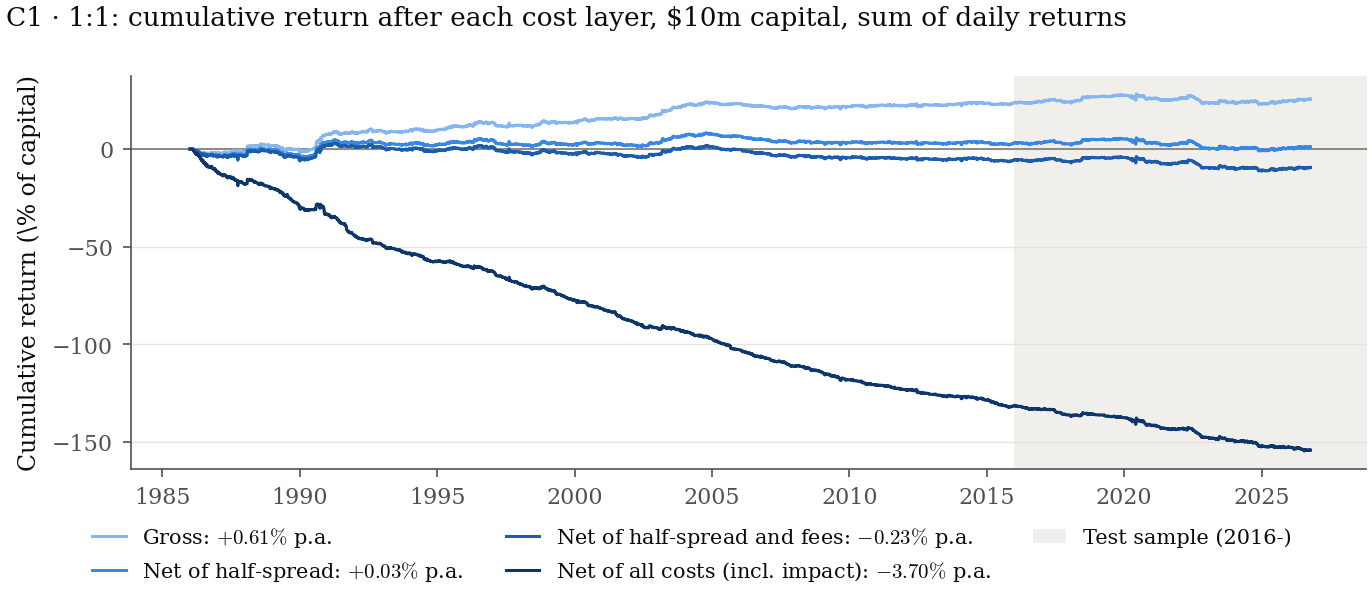

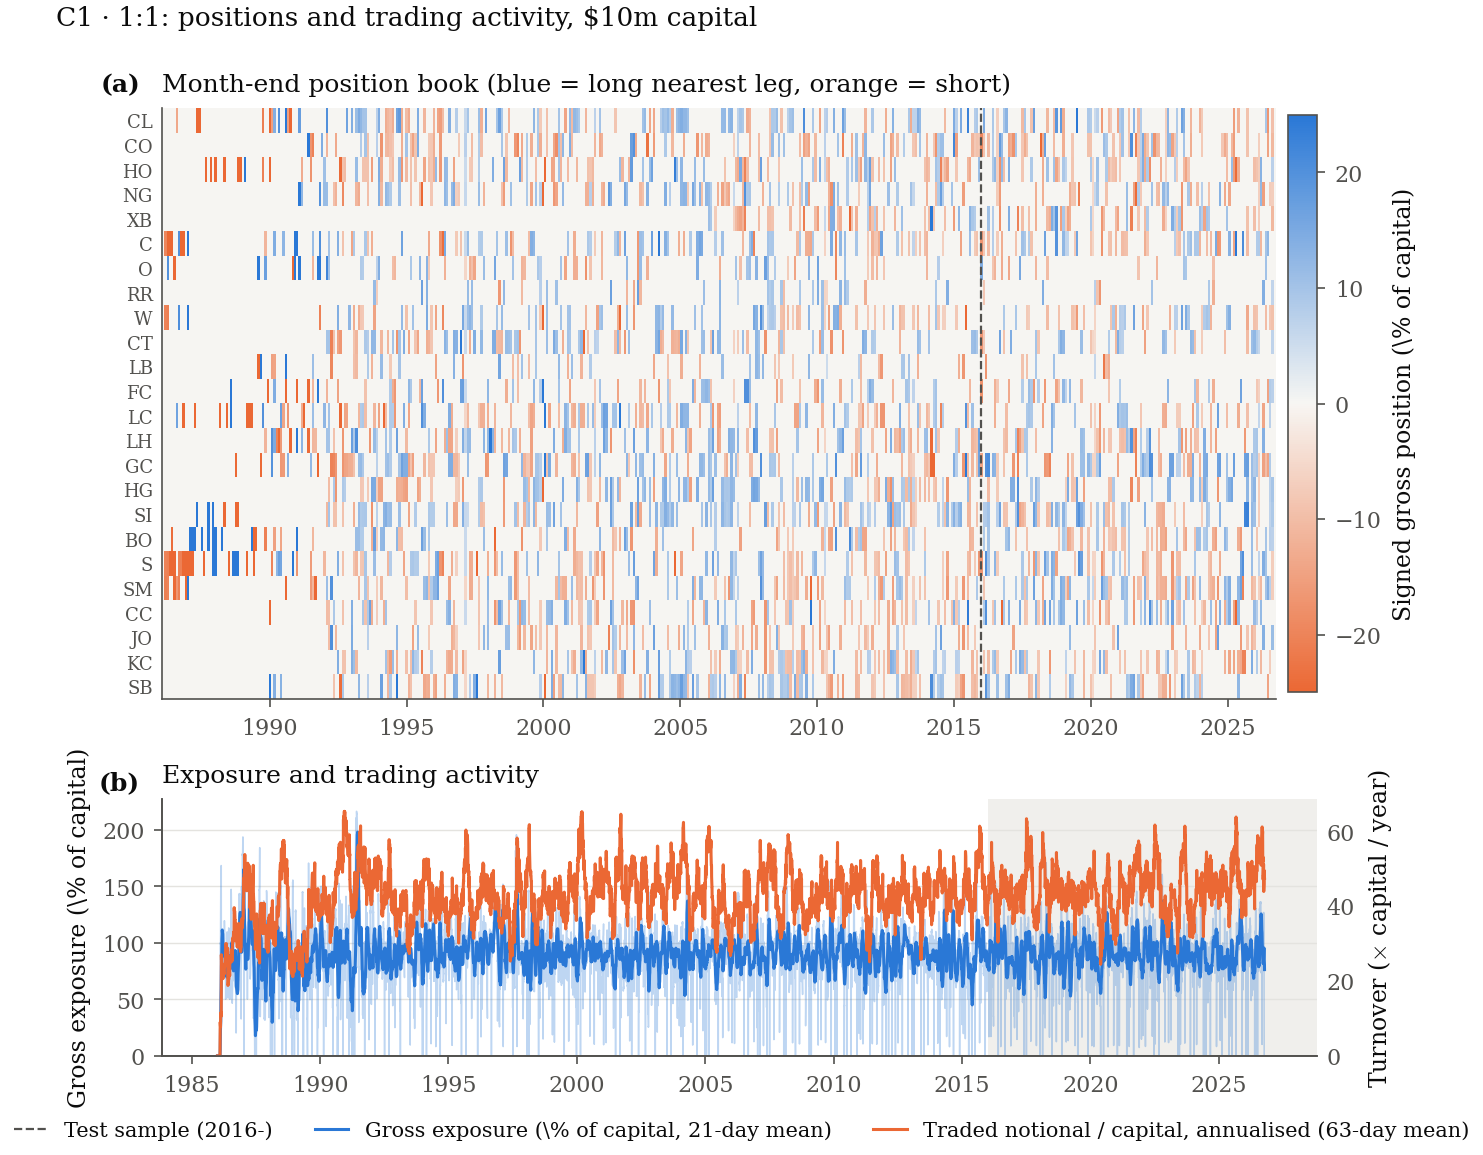

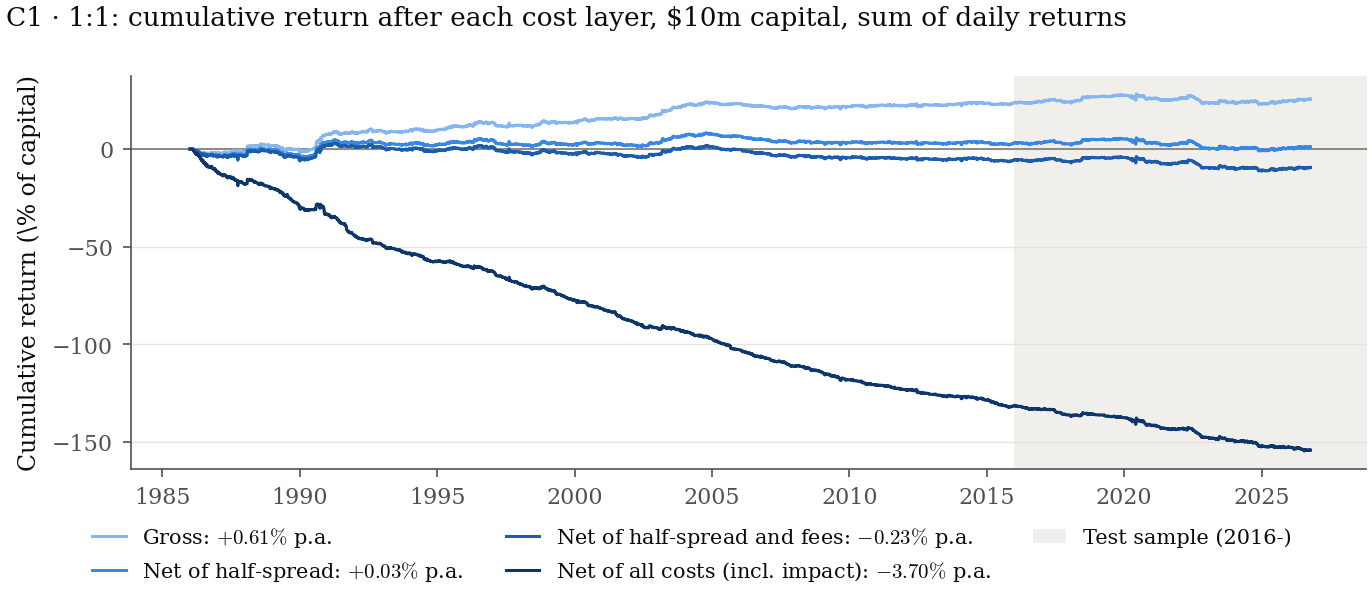

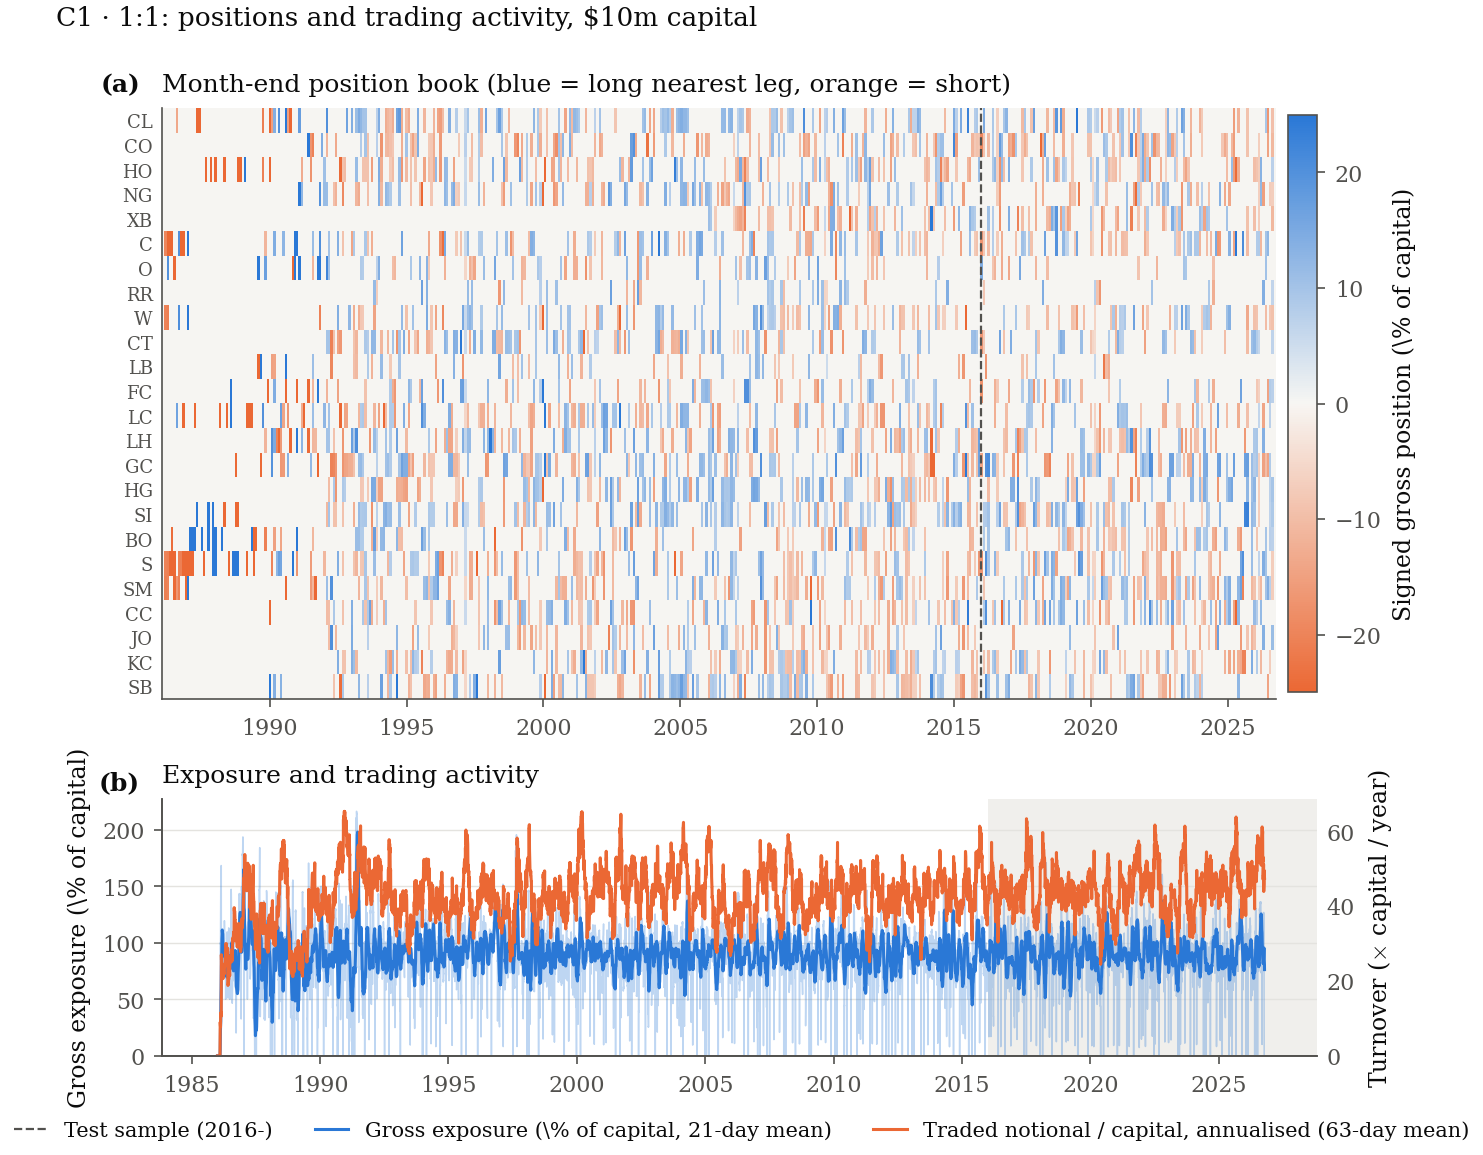

In [5]:
show_variant("c", "C1 · 1:1")


## 6. C2 · Rolling OLS


,Ann. ret (%),Ann. vol (%),Max DD (%),Turnover (x/yr)
layer,,,,
gross,0.124,1.169,-5.150,42.738
- half-spread,-0.449,1.172,-19.207,42.738
- fees,-0.693,1.174,-29.330,42.738
- impact (all),-3.060,1.266,-127.761,42.738


Overall Sharpe (full sample, all-in net): -2.417


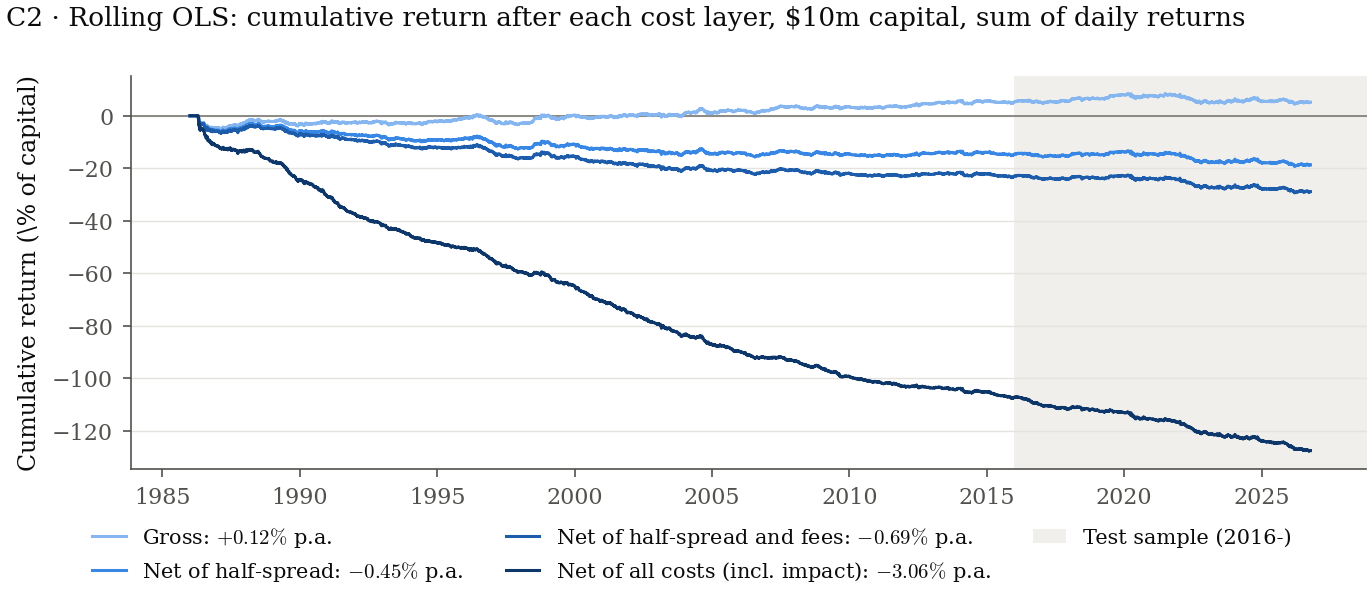

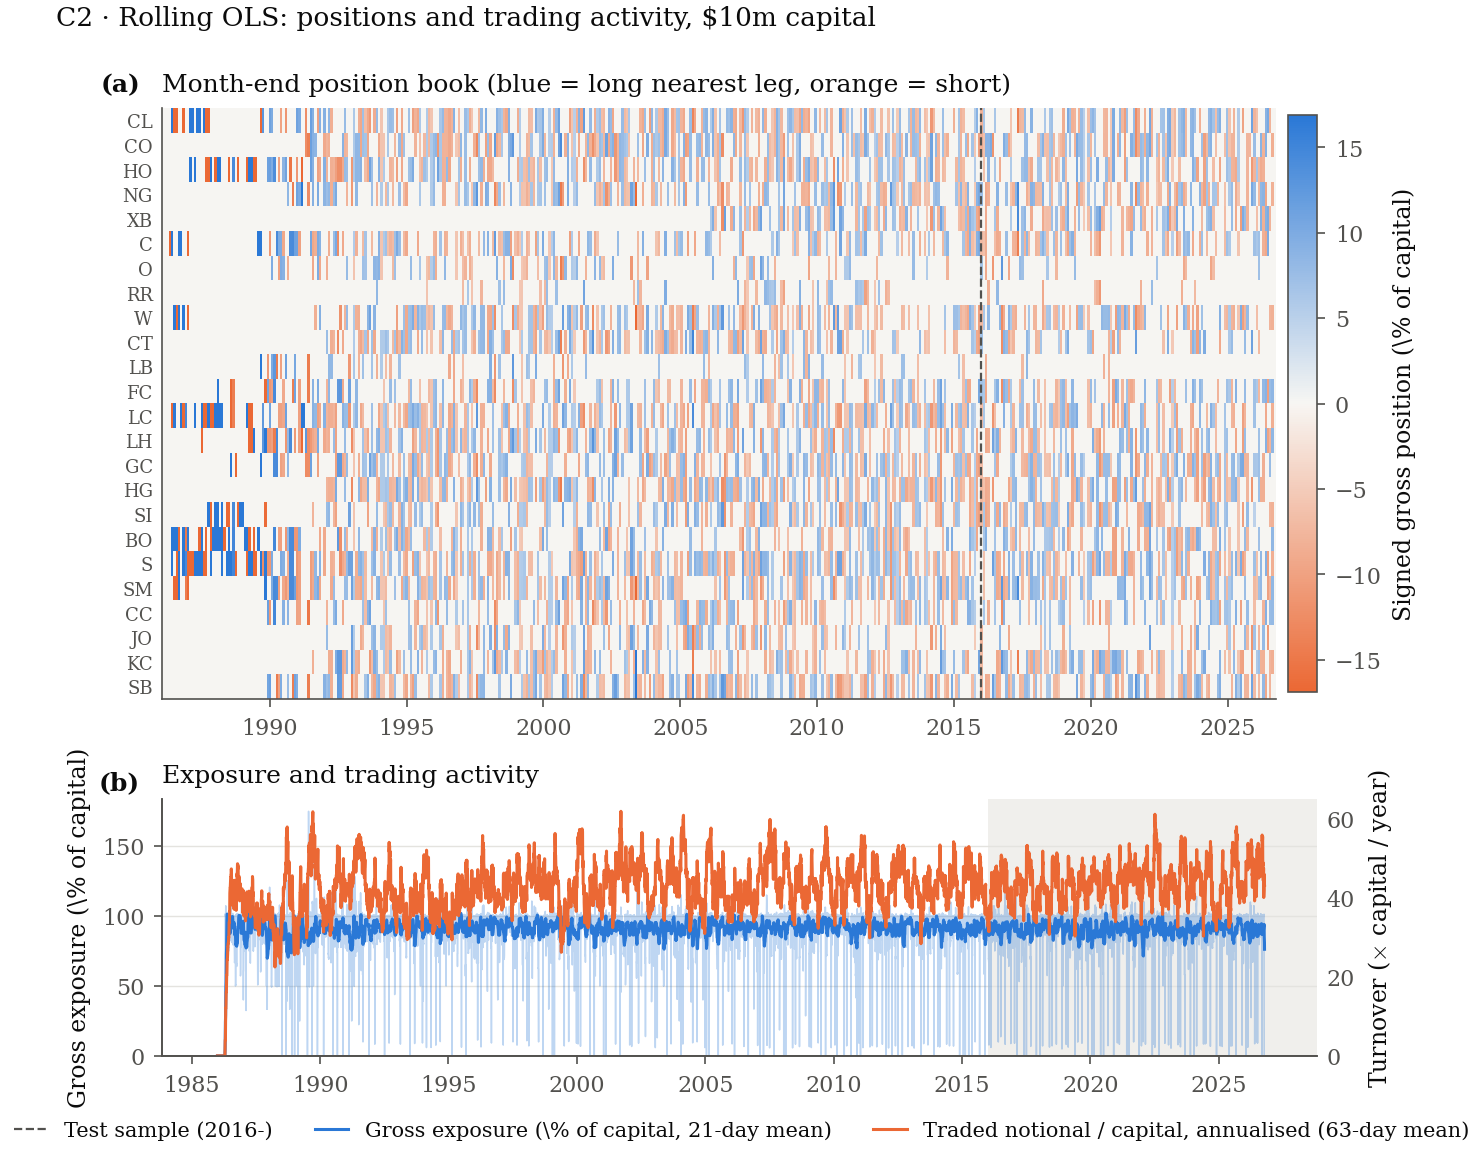

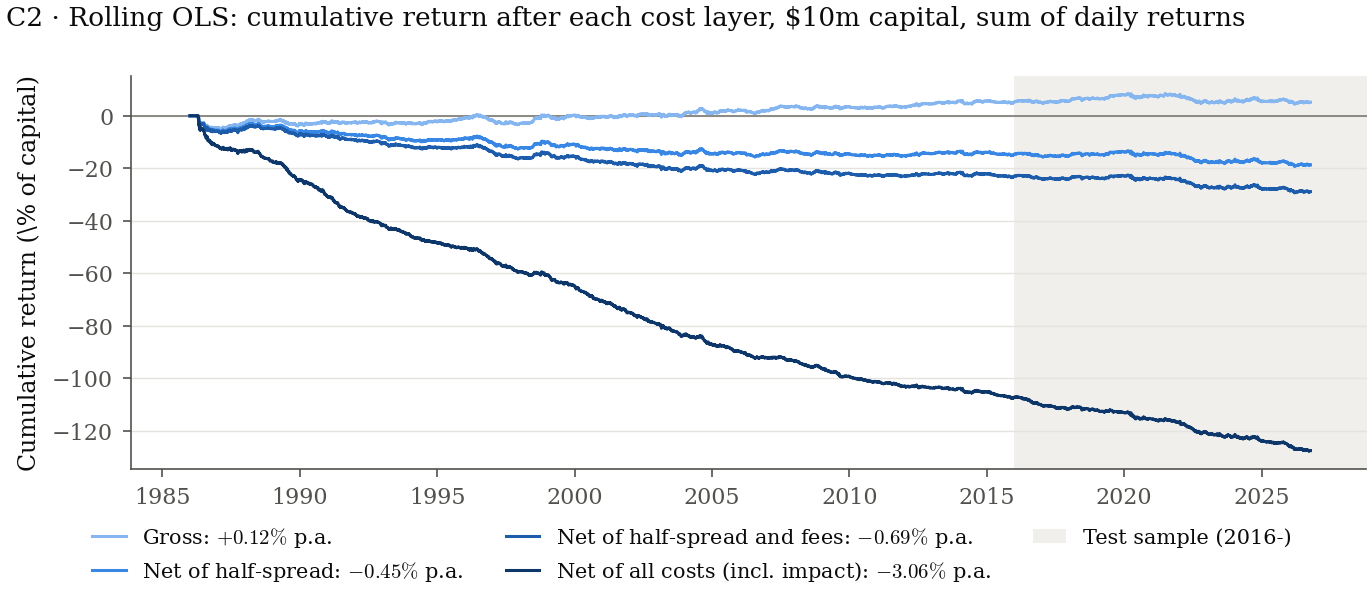

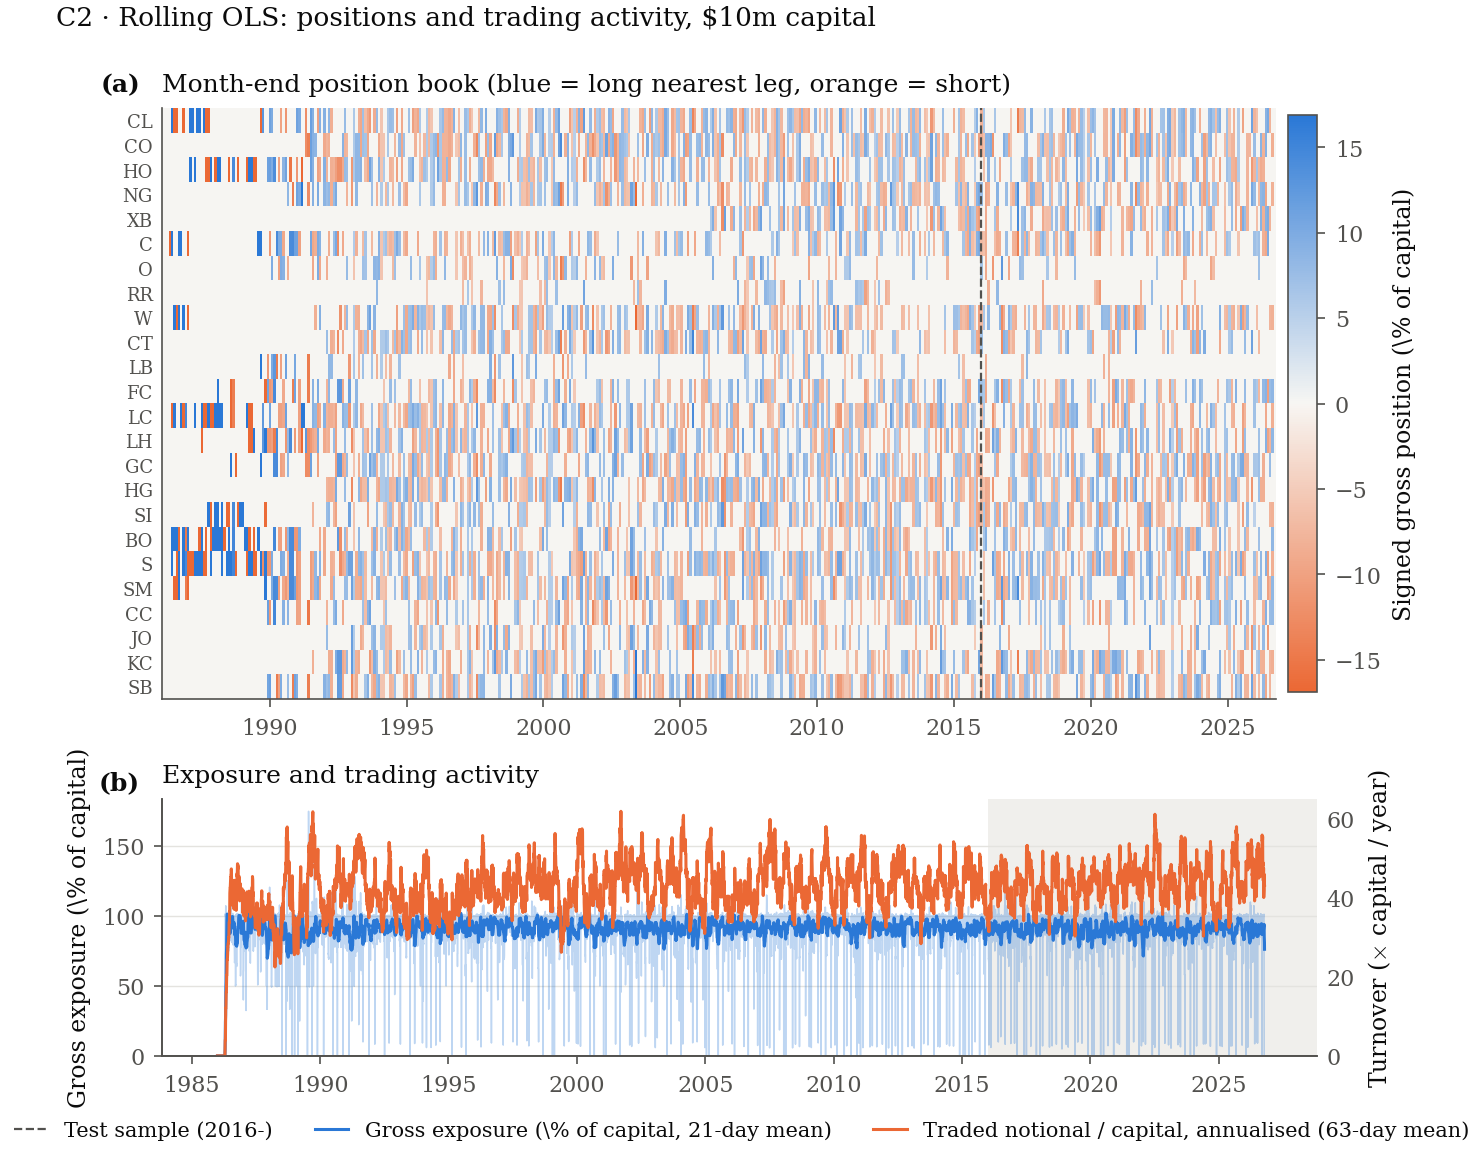

In [6]:
show_variant("c_ols", "C2 · Rolling OLS")


## 7. C3 · Kalman


,Ann. ret (%),Ann. vol (%),Max DD (%),Turnover (x/yr)
layer,,,,
gross,0.613,2.446,-11.014,54.716
- half-spread,-0.175,2.447,-15.498,54.716
- fees,-0.497,2.448,-25.800,54.716
- impact (all),-6.099,2.724,-254.559,54.716


Overall Sharpe (full sample, all-in net): -2.239


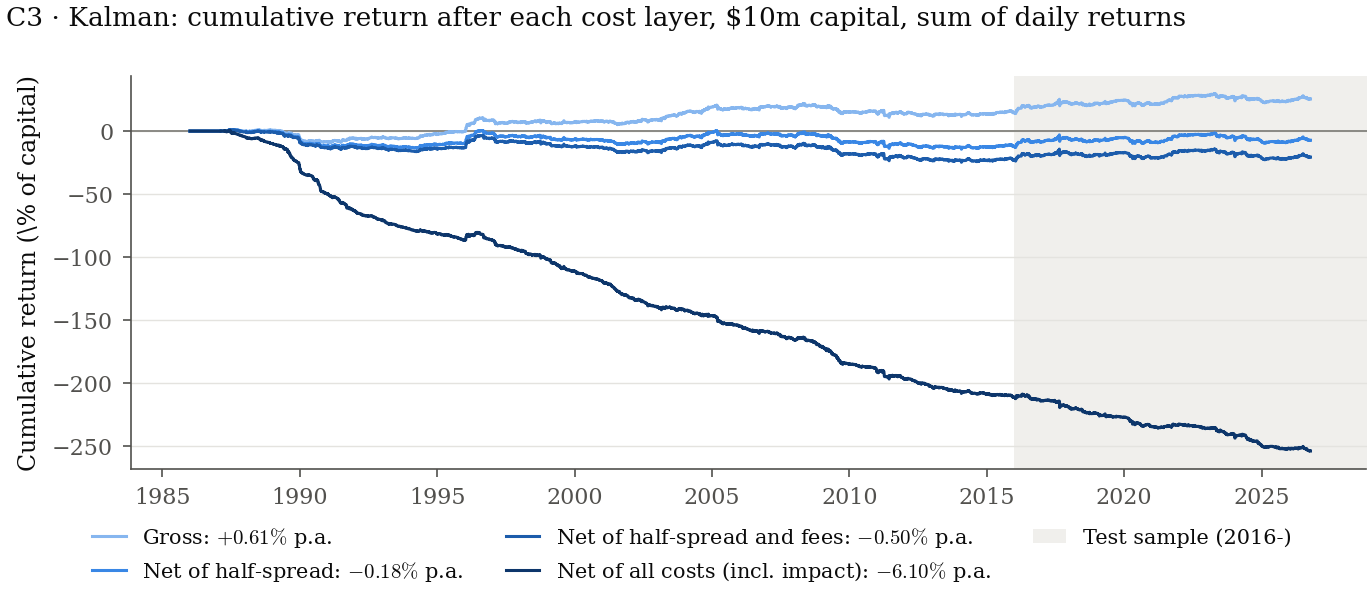

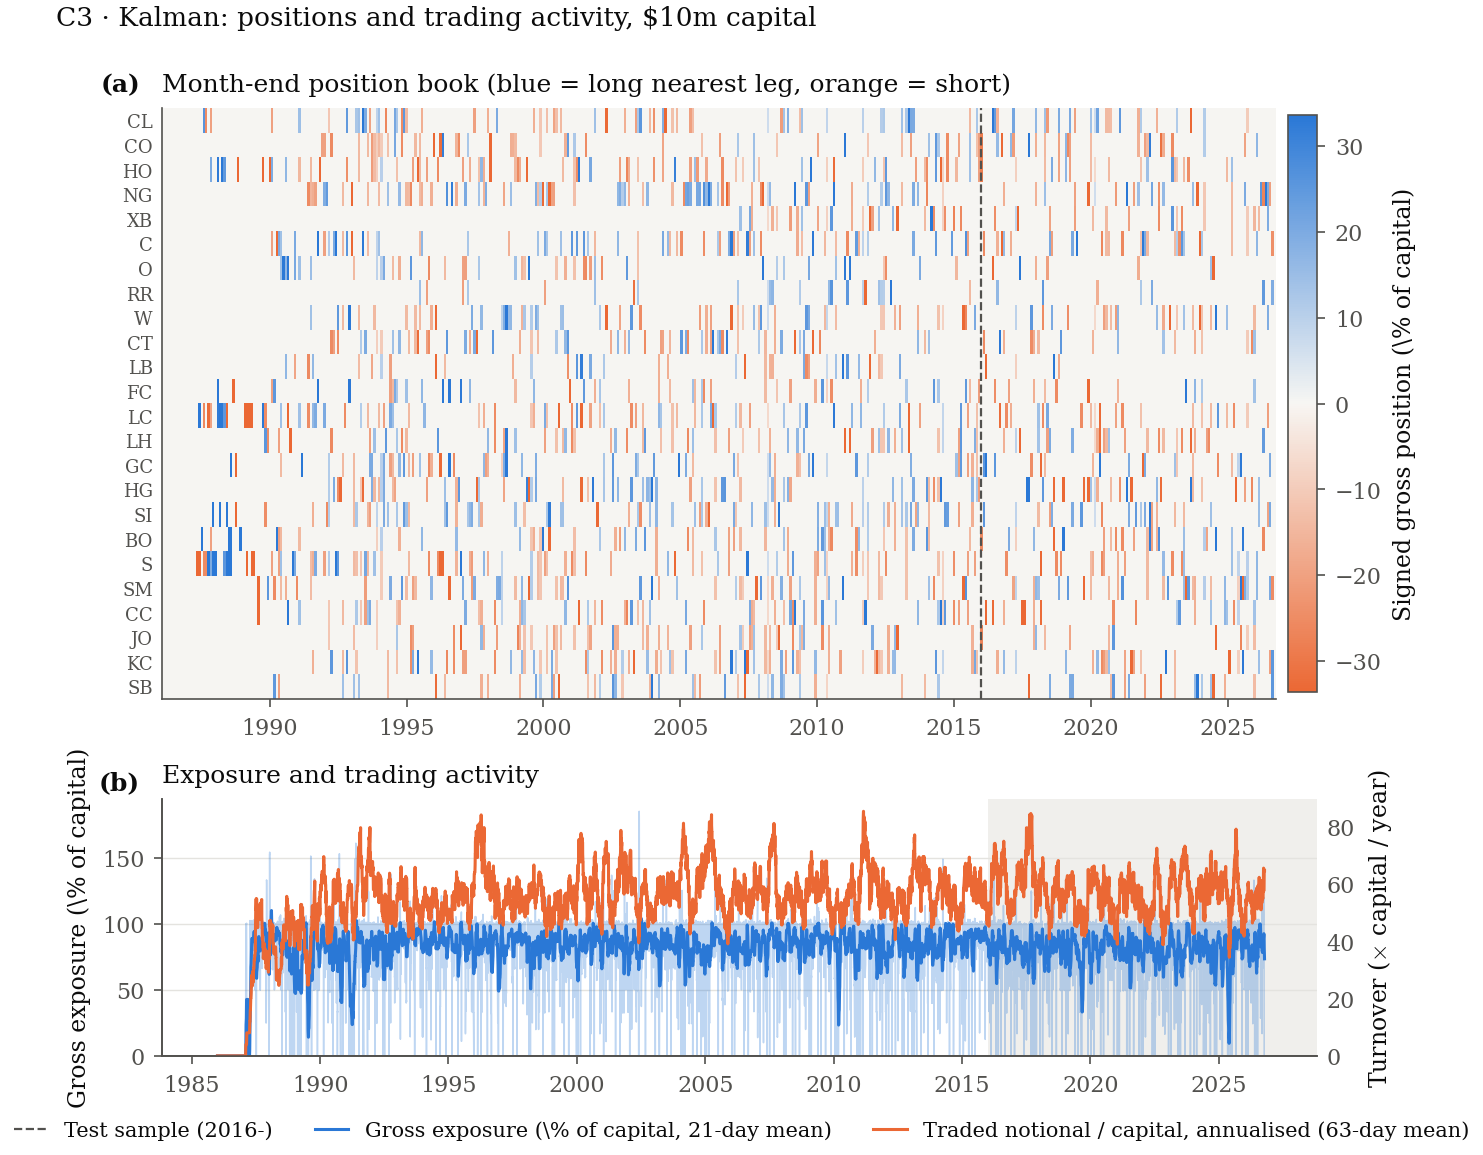

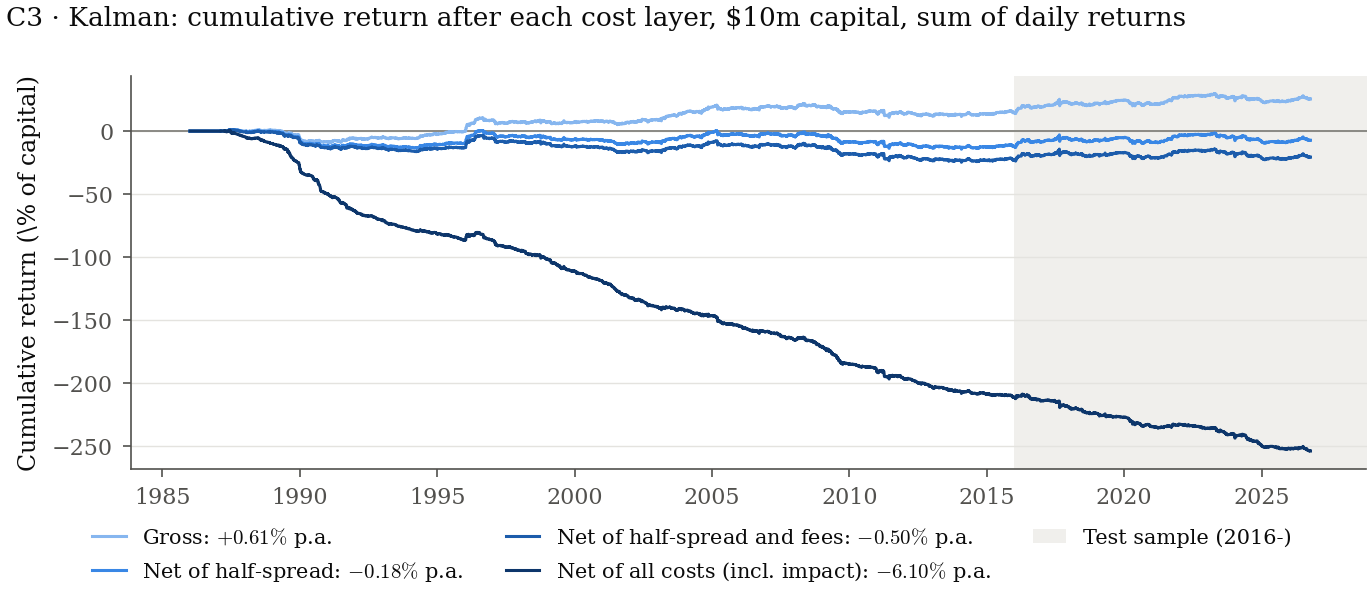

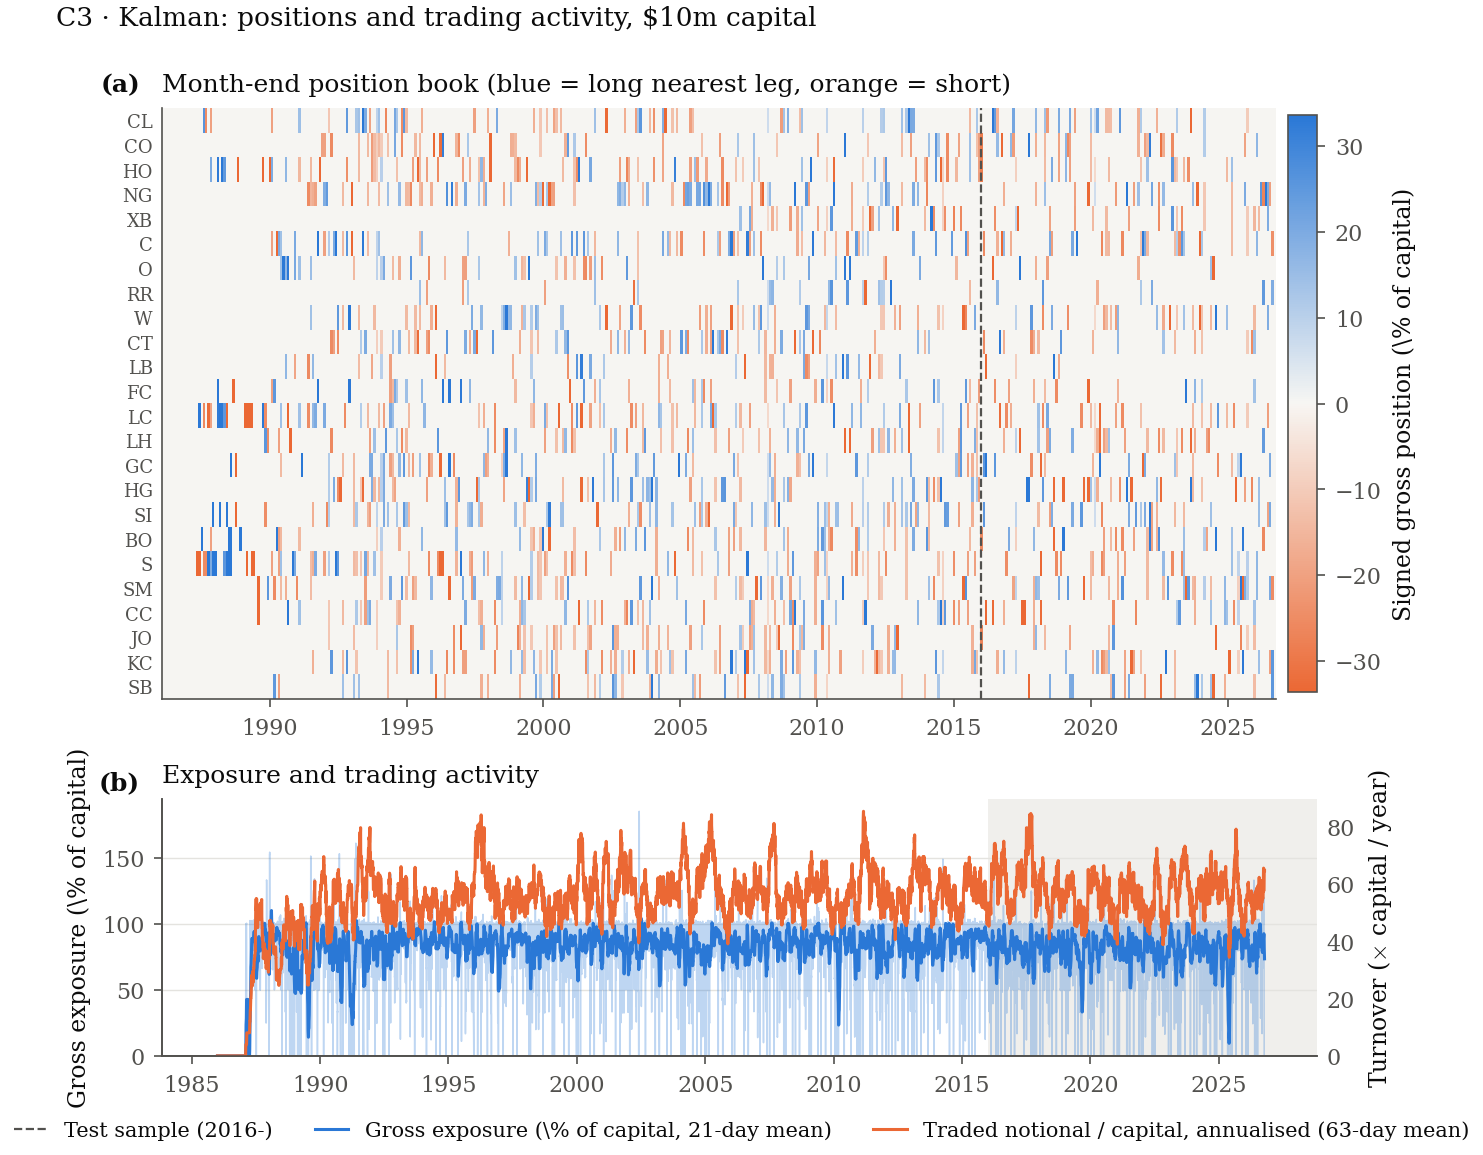

In [7]:
show_variant("c_kalman", "C3 · Kalman")


## 8. 解读 / Reading

C 是 **closed mixed/negative**：1:1 的 full-sample gross 略为正，但 all-in
net 为负；rolling OLS 和 Kalman 都没有 rescue。Kalman 的 gross 与 1:1
接近，但 turnover 和成本更高，all-in net 更差。C 不再做 daily paper
replication；如果以后重开，是独立的 pre-registered 项目。

- C baseline、OLS、Kalman 的历史细节：`docs/HANDOFF.md`、
  `docs/logs/`（LOG-0013–0018、LOG-0022–0026）。
- v1/v2 对照：`docs/v1_v2_comparison.md`。
- 旧 notebook 已 retired；恢复方式见 `docs/notebook_history.md`。


## 9. Daily information audit（D-027）

这一节与上面的官方 weekly 结果**分开**：D-019 的 weekly 表仍是正式结果。
这里把 C 的信号层换成 daily（z 和 h 每天更新，t+1 成交），只做 gross，
先回答“C 有多少信息、值不值得继续做 alpha”。

- 样本：1986–2005 训练/探索；2006–2015 validation；2016–2026 test 只看一次。
- 变体：C1 1:1 / C2 rolling OLS / C3 Kalman；参数保持 L=20、entry=2、exit=0。
- 不做 grid search；weekly vs daily 只作对照，daily 结果保留。
- 复现：`python scripts/run_c_daily_audit.py --stage stage1`。Stage 1 把 marks
  截断在 2015-12-31，不会读 test；只有 validation gate 通过后，stage 2 才读一次 test。
- D-029 的 full-sample artifacts 和 descriptive 图见第 12 节。


### 9.1 Validation selection and alpha gate

采用规则是顺序升级：C2 要取代 C1，必须在 validation 上同时满足
(a) gross SR 至少高 0.05，(b) daily return 差值的 21 天 block-bootstrap
95% CI 下界 > 0，(c) ≥60% eligible roots 改善；C2 没过再比较 C3 与 C1。
最终选中的变体还必须过 alpha gate：validation gross SR ≥0.4、
≥60% eligible roots 为正、test gross SR >0。

In [8]:
import json

AUDIT = config.OUTPUT_DIR / "c_daily_audit"
S1 = AUDIT / "stage1_train_validation"
if not (S1 / "gate.json").exists():
    print("Run: python scripts/run_c_daily_audit.py --stage stage1")
else:
    selection = pd.read_csv(S1 / "selection.csv")
    gate = json.loads((S1 / "gate.json").read_text())
    display(selection.round(3))
    display(pd.DataFrame([gate]).T)

,step,binding,current,new,sr_current,sr_new,sr_gain,diff_mean_bps,ci_lo_bps,ci_hi_bps,p_value,breadth,n_roots,pass_sr,pass_bootstrap,pass_breadth,passed,selected_after
0,C2 vs C1,True,1:1,ols,0.24,0.265,0.025,-0.004,-0.249,0.235,0.968,0.500,24,False,False,False,False,1:1
1,C3 vs C1,True,1:1,kalman,0.24,-0.332,-0.572,-0.338,-0.747,0.090,0.134,0.375,24,False,False,False,False,1:1


,0
selected,1:1
validation_sr,0.239824
validation_breadth,0.625
n_positive_roots,15
n_eligible_roots,24
pass_validation,False
test_read,False


### 9.2 Gross performance by variant and period

Stage 1 only reports train and validation; the test row is intentionally absent.

In [9]:
if (S1 / "gate.json").exists():
    frames = []
    for name in ("c1", "c2", "c3"):
        frame = pd.read_csv(S1 / f"{name}_performance.csv")
        frame = frame.loc[frame["layer"].eq("gross")].copy()
        frame["variant"] = name
        frames.append(frame)
    display(
        pd.concat(frames)[
            ["variant", "period", "ann_ret_pct", "ann_vol_pct", "sharpe", "t_nw", "turnover_x"]
        ].round(3)
    )

,variant,period,ann_ret_pct,ann_vol_pct,sharpe,t_nw,turnover_x
0,c1,train 1986-2005,0.525,1.504,0.349,1.682,54.036
4,c1,validation 2006-2015,0.229,0.956,0.240,0.795,54.697
8,c1,train+validation 1986-2015,0.426,1.346,0.317,1.860,54.257
0,c2,train 1986-2005,-0.195,1.230,-0.159,-0.706,47.656
4,c2,validation 2006-2015,0.219,0.826,0.265,0.875,50.732
8,c2,train+validation 1986-2015,-0.057,1.111,-0.051,-0.280,48.685
0,c3,train 1986-2005,0.271,1.549,0.175,0.833,73.219
4,c3,validation 2006-2015,-0.623,1.878,-0.332,-1.067,79.520
8,c3,train+validation 1986-2015,-0.028,1.666,-0.017,-0.098,75.327


### 9.3 Information diagnostics

- Event study：fresh entry / flip，long/short 分开，1/5/10/20 天 signed return。
- IC：`−z` 对 forward return，per-root + block bootstrap。
- Timing：`[t,t+1]`（same-settle，不可交易）vs `[t+1,t+2]`（可交易）。
- Persistence：spread level 和 z 的 AR(1) half-life。
- Nested regression：z vs z+carry vs z+momentum。
- Placebo：circular shift 的 execution-free SR 分布。

In [10]:
if (S1 / "gate.json").exists():
    events = pd.concat(
        {name: pd.read_csv(S1 / f"{name}_event_study.csv") for name in ("c1", "c2", "c3")},
        names=["variant"],
    ).reset_index()
    display(events.loc[events["event"].eq("fresh")].round(2))

,variant,level_1,event,side,horizon_days,mean_bps,median_bps,hit_rate,t_nw,n_events,n_dates
0,c1,0,fresh,all,1,0.55,0.00,0.48,1.30,2124,1409
1,c1,1,fresh,all,5,0.11,0.26,0.51,0.82,2122,1407
2,c1,2,fresh,all,10,-2.68,-0.05,0.50,-0.07,1987,1336
3,c1,3,fresh,all,20,-1.62,-0.08,0.50,-0.33,1537,1109
4,c1,4,fresh,long,1,1.99,0.00,0.47,1.68,987,773
5,c1,5,fresh,long,5,6.18,-0.18,0.49,2.15,985,771
6,c1,6,fresh,long,10,6.25,-0.42,0.49,1.90,923,725
7,c1,7,fresh,long,20,5.24,0.15,0.50,0.87,749,606
8,c1,8,fresh,short,1,-0.71,0.00,0.48,0.27,1137,886
9,c1,9,fresh,short,5,-5.15,0.64,0.52,-0.65,1137,886


#### Timing：信息能不能扛过一天执行延迟

同一组 daily target，比较 `[t,t+1]`（信号自己的 settle，不可交易）和
`[t+1,t+2]`（t+1 成交后第一个可交易日）。如果 edge 只在 `[t,t+1]`，
它更像 settlement 同步问题，而不是可交易 alpha。

In [11]:
if (S1 / "gate.json").exists():
    timing = pd.concat(
        {name: pd.read_csv(S1 / f"{name}_timing.csv") for name in ("c1", "c2", "c3")},
        names=["variant"],
    ).reset_index()
    display(timing.loc[timing["period"].eq("validation 2006-2015")].round(3))

,variant,level_1,period,timing,window,ann_ret_pct,ann_vol_pct,sharpe,t_nw,days
5,c1,5,validation 2006-2015,"same-settle [t,t+1]",fwd_0_1,0.425,1.012,0.419,1.327,2543
6,c1,6,validation 2006-2015,"tradable [t+1,t+2]",fwd_1_2,0.066,1.031,0.064,0.204,2542
7,c1,7,validation 2006-2015,t+1..t+6,fwd_1_6,-0.348,2.391,-0.146,-0.269,2538
8,c1,8,validation 2006-2015,t+1..t+11,fwd_1_11,0.544,3.354,0.162,0.268,2522
9,c1,9,validation 2006-2015,t+1..t+21,fwd_1_21,-0.032,4.618,-0.007,-0.011,2498
15,c2,5,validation 2006-2015,"same-settle [t,t+1]",fwd_0_1,0.179,0.834,0.215,0.693,2559
16,c2,6,validation 2006-2015,"tradable [t+1,t+2]",fwd_1_2,0.126,0.842,0.150,0.495,2558
17,c2,7,validation 2006-2015,t+1..t+6,fwd_1_6,-0.238,1.961,-0.122,-0.228,2554
18,c2,8,validation 2006-2015,t+1..t+11,fwd_1_11,-0.109,2.748,-0.040,-0.066,2536
19,c2,9,validation 2006-2015,t+1..t+21,fwd_1_21,-2.146,3.980,-0.539,-0.841,2500


#### IC 与 block bootstrap

`score = −z`：z 越低（spread 越低于均值），越应该做多 spread，所以预期 IC 为正。

In [12]:
if (S1 / "c1_ic.csv").exists():
    ic = pd.read_csv(S1 / "c1_ic.csv")
    display(ic.loc[ic["root"].eq("ALL")].round(4))
    display(
        ic.loc[~ic["root"].eq("ALL")]
        .groupby("horizon_days")[["ic", "t_nw", "ci_lo", "ci_hi"]]
        .median()
        .round(4)
    )

,horizon_days,root,ic,t_nw,n,ci_lo,ci_hi,p_value
24,1,ALL,0.0095,NaN,60223,NaN,NaN,NaN
49,5,ALL,0.0027,NaN,60127,NaN,NaN,NaN
74,10,ALL,-0.0009,NaN,56807,NaN,NaN,NaN
99,20,ALL,0.0209,NaN,44940,NaN,NaN,NaN


,ic,t_nw,ci_lo,ci_hi
horizon_days,,,,
1,0.0119,0.5694,-0.0271,0.0514
5,-0.0145,-0.4278,-0.0873,0.0621
10,-0.0132,-0.3356,-0.1016,0.0828
20,0.0148,0.2261,-0.0884,0.1193


In [13]:
if (S1 / "c1_persistence.csv").exists():
    persistence = pd.read_csv(S1 / "c1_persistence.csv")
    display(
        persistence[["phi_level", "half_life_level", "phi_z", "half_life_z"]]
        .describe()
        .round(3)
    )
    nested = pd.read_csv(S1 / "c1_nested_r2.csv")
    display(
        nested.groupby("model")[["r2", "adj_r2", "oos_r2"]]
        .median()
        .round(4)
    )
    placebo = json.loads((S1 / "c1_placebo.json").read_text())
    display(pd.DataFrame([placebo]).T)

,phi_level,half_life_level,phi_z,half_life_z
count,24.000,23.000,24.000,24.000
mean,0.998,2179.344,0.842,4.276
std,0.002,5510.078,0.040,1.076
min,0.991,80.202,0.745,2.356
25%,0.997,259.441,0.822,3.543
50%,0.999,506.998,0.847,4.176
75%,0.999,922.870,0.877,5.279
max,1.000,26240.611,0.895,6.242


,r2,adj_r2,oos_r2
model,,,
M0_z,0.0018,0.0009,-0.0068
M1_z_carry,0.0118,0.0106,-0.0302
M2_z_mom,0.0052,0.0040,-0.0149
M3_z_both,0.0164,0.0148,-0.0304


,0
actual_sr,0.064155
placebo_mean_sr,-0.072652
placebo_sd_sr,0.314084
placebo_p025_sr,-0.709216
placebo_p975_sr,0.551385
p_one_sided,0.328000
p_two_sided,0.656000
n_draws,1000.000000
min_shift,63.000000


### 9.4 Weekly vs daily

Daily 是新的标准口径，weekly 只作对照；不管比较结果如何，daily 结果都保留。
Weekly 数字来自现有 `v2_rerun`，不修改 D-019 的正式表。

In [14]:
if (S1 / "weekly_vs_daily.csv").exists():
    display(pd.read_csv(S1 / "weekly_vs_daily.csv").round(3))

,method,frequency,ann_ret_pct,ann_vol_pct,sharpe,t_nw,turnover_x,n_days
0,1:1,weekly,0.054,1.183,0.046,0.153,43.468,2583
1,ols,weekly,0.308,0.914,0.338,1.108,43.829,2583
2,kalman,weekly,-0.378,2.553,-0.148,-0.466,57.482,2583
3,1:1,daily,0.229,0.956,0.240,0.795,54.697,2583
4,ols,daily,0.219,0.826,0.265,0.875,50.732,2583
5,kalman,daily,-0.623,1.878,-0.332,-1.067,79.520,2583


## 10. Test read（只读一次）

Stage 2 只有在 validation gate 通过、且显式传 `--confirm-read-once` 时才会读
2016–2026 test。D-029 的 full-sample descriptive run 也会写同一个 marker；
**marker 存在不等于 gate 通过**，两种 read 的 `reason` 可以区分。marker 顶层
`test_read=True` 表示做过 descriptive read；嵌套的 `gate.test_read` 仍是
D-027 的 validation-only 字段。下面的 cell 只读取已经写好的 marker，
不会重新跑模拟。


In [15]:
marker = AUDIT / "test_readonce.json" if (S1 / "gate.json").exists() else None
if marker is not None and marker.exists():
    display(pd.DataFrame([json.loads(marker.read_text())]).T)
else:
    gate_path = S1 / "gate.json"
    if gate_path.exists():
        gate = json.loads(gate_path.read_text())
        print("Test not read. Validation gate:", gate["pass_validation"])
    else:
        print("Run: python scripts/run_c_daily_audit.py --stage stage1")

,0
read_at_utc,2026-10-20T14:37:25.508618+00:00
reason,descriptive full-sample presentation
stage,full
selected,1:1
gate,"{'selected': '1:1', 'validation_sr': 0.2398236..."
test_read,True
commit,1b757282d117d5a73ca5a26f00ddb56c510976a6


## 11. Daily audit reading

**Stage 1 结论：C daily 没有过 alpha gate。**

- Daily validation gross SR：C1 **0.240**、C2 **0.265**、C3 **−0.332**。
- Weekly 对照（2006–2015）：C1 **0.046**、C2 **0.338**、C3 **−0.148**。
  Daily 改善了 C1，但 C2/C3 反而更差；C1 的 0.240 仍低于 0.4 gate。
- 顺序选择：C2 vs C1 只高 0.025（<0.05），paired diff CI 含 0，breadth
  50%；C3 vs C1 更差。最终保留 **C1**。
- Gate：C1 validation gross SR **0.240 < 0.4**；15/24 roots 为正
  （62.5%），广度过了，但绝对 SR 不够。D-027 stage-1 结束时 test 未读。

**信息诊断：**

- IC：ALL 的 1/5/10/20 天 IC 为 **0.0095 / 0.0027 / −0.0009 /
  0.0209**；per-root median 的 95% CI 都含 0。
- Timing：validation 的 same-settle SR **0.419**，可交易 `[t+1,t+2]`
  只有 **0.064**；`t+1..t+11` 0.162，`t+1..t+21` ≈0。大部分“信息”
  在不可交易的 same-settle 窗口里。
- Event study：fresh long 10 天 **+6.2 bps**，fresh short **−10.4 bps**；
  对称信号的 short 端是拖累。
- Nested R²：z alone 的 OOS R² 为负；加 carry/momentum 只在样本内提高
  adjusted R²，OOS R² 反而更差。
- Placebo：execution-free tradable SR 0.064；placebo mean −0.073，
  two-sided p **0.656**，和随机 timing 没有区别。
- Jackknife：drop NG/CT/CC 后 SR 降到 0.119–0.122；drop LH 后升到
  0.448。Edge 集中在少数 root，不是 broad 的稳定信号。

因此 C 作为 daily alpha 不成立；daily 结果保留，C 保持 closed。
下一步不做 cost/alpha，除非提出新的、独立预注册的假设（例如单独的
long-only 或不同 exit 规则），而不是在这个 gate 上继续调参。

**D-029 full-sample update（2026-10-20）：** 为了补齐 daily artifacts 和
notebook 图，2016–2026 test 已在 full stage 中 **descriptive read once**。
这不改变上面的 gate 结论，也不改变 official weekly D-019 结果；C 仍是
closed。Test 数字只在第 12 节作为描述性展示，不能用于调参或重新选择变体。


## 12. Daily signal artifacts（full sample，descriptive；D-029）

**这一节不是新的 official result，也不是新的 gate。** D-027 的 validation gate
仍然失败（C1 validation gross SR 0.240 < 0.4），official weekly 结果（D-019）
不变，C 仍为 closed。本节只是为了完整展示 daily 信号：把 C1/C2/C3 在
**full sample 1986–2026** 上各跑一次（零成本、USD 10m），读取已经保存的
signal / legs / daily P&L / positions artifacts，并补上 NAV 和持仓图。

**2016–2026 是 test sample，只读一次，仅作 descriptive presentation。**
图中的阴影和 summary 表的 test 行都不能用于调参、变体选择或重新判定 gate。
D-029 的 test read 记录在 `output/c_daily_audit/test_readonce.json`；
第二次读取需要显式 `--force-test-read`。

- 复现：`python scripts/run_c_daily_audit.py --stage full --confirm-read-once`
- Artifacts：`output/c_daily_audit/full/`（signals / legs / daily / positions /
  performance / root）；manifest：`output/c_daily_audit/manifest_full.json`


In [16]:
from src import c_daily

FULL = AUDIT / "full"
FULL_NAMES = {"c1": "C1 · 1:1", "c2": "C2 · Rolling OLS", "c3": "C3 · Kalman"}
full_loaded = {}
if (FULL / "signals" / "c1.parquet").exists():
    full_loaded = {
        name: c_daily.load_variant_artifacts(name, FULL)
        for name in FULL_NAMES
    }
    manifest_full = json.loads((AUDIT / "manifest_full.json").read_text())
    print(
        "sample:", manifest_full["sample"],
        "| reason:", manifest_full["reason"],
        "| selected (D-027):", manifest_full["selected"],
        "| gate passed:", manifest_full["gate"]["pass_validation"],
    )
    marker_path = AUDIT / "test_readonce.json"
    if marker_path.exists():
        display(pd.DataFrame([json.loads(marker_path.read_text())]).T)
    else:
        print("test read marker missing:", marker_path)
else:
    print("Run: python scripts/run_c_daily_audit.py --stage full --confirm-read-once")


sample: 1986-01-01..2026-10-13 | reason: descriptive full-sample presentation | selected (D-027): 1:1 | gate passed: False


,0
read_at_utc,2026-10-20T14:37:25.508618+00:00
reason,descriptive full-sample presentation
stage,full
selected,1:1
gate,"{'selected': '1:1', 'validation_sr': 0.2398236..."
test_read,True
commit,1b757282d117d5a73ca5a26f00ddb56c510976a6


### 12.1 Gross NAV

三个变体的 full-sample cumulative gross return（sum of daily returns，
零成本，USD 10m capital）。2016–2026 阴影是 descriptive test slice，
不是新的 official out-of-sample result。


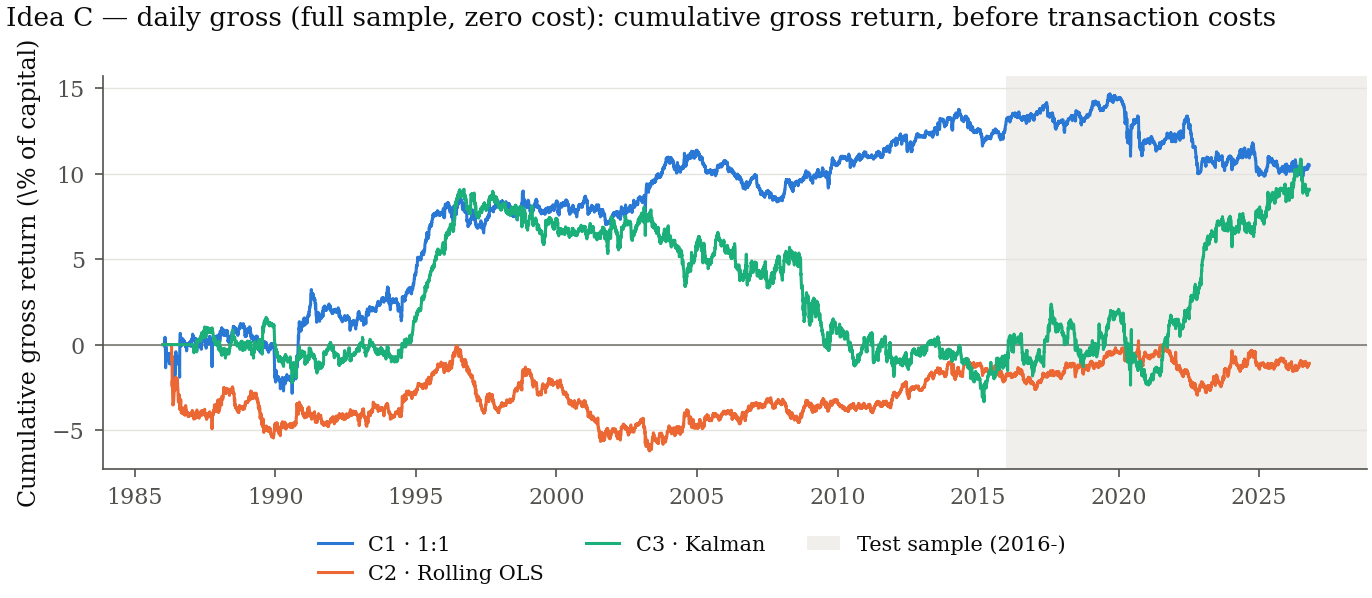

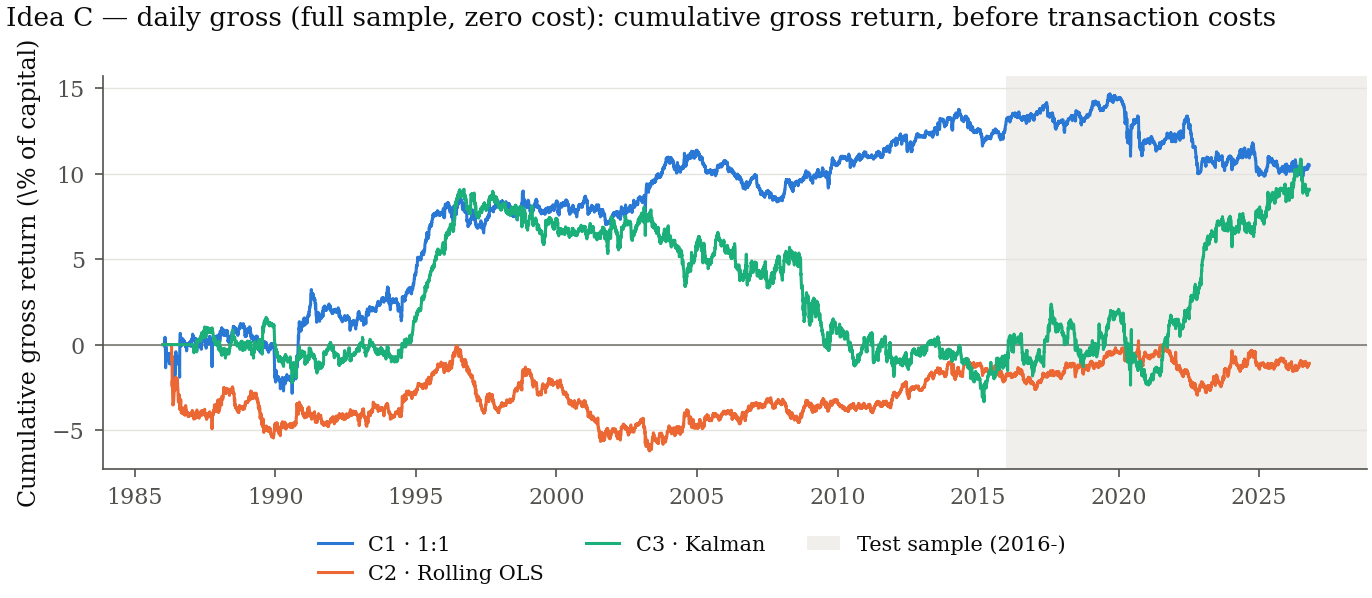

In [17]:
if full_loaded:
    nav_series = {
        FULL_NAMES[name]: frame["daily"].set_index("date")["ret_gross"]
        for name, frame in full_loaded.items()
    }
    fig = F.nav_compare(
        nav_series,
        "Idea C — daily gross (full sample, zero cost)",
        test_start="2016-01-01",
    )
    ps.save(fig, "idea_c_daily_full_nav")
    display(fig)


### 12.2 Positions、exposure 和 turnover

每个变体一张 `F.positions` 图：上面是 month-end signed position heatmap
（蓝=long nearest leg，橙=short；大小是 gross notional / capital），
下面是组合 gross exposure（% of capital）和年化 turnover。ROOT_ORDER 与
其他 idea notebook 一致。阴影 2016–2026 只表示 descriptive test slice。


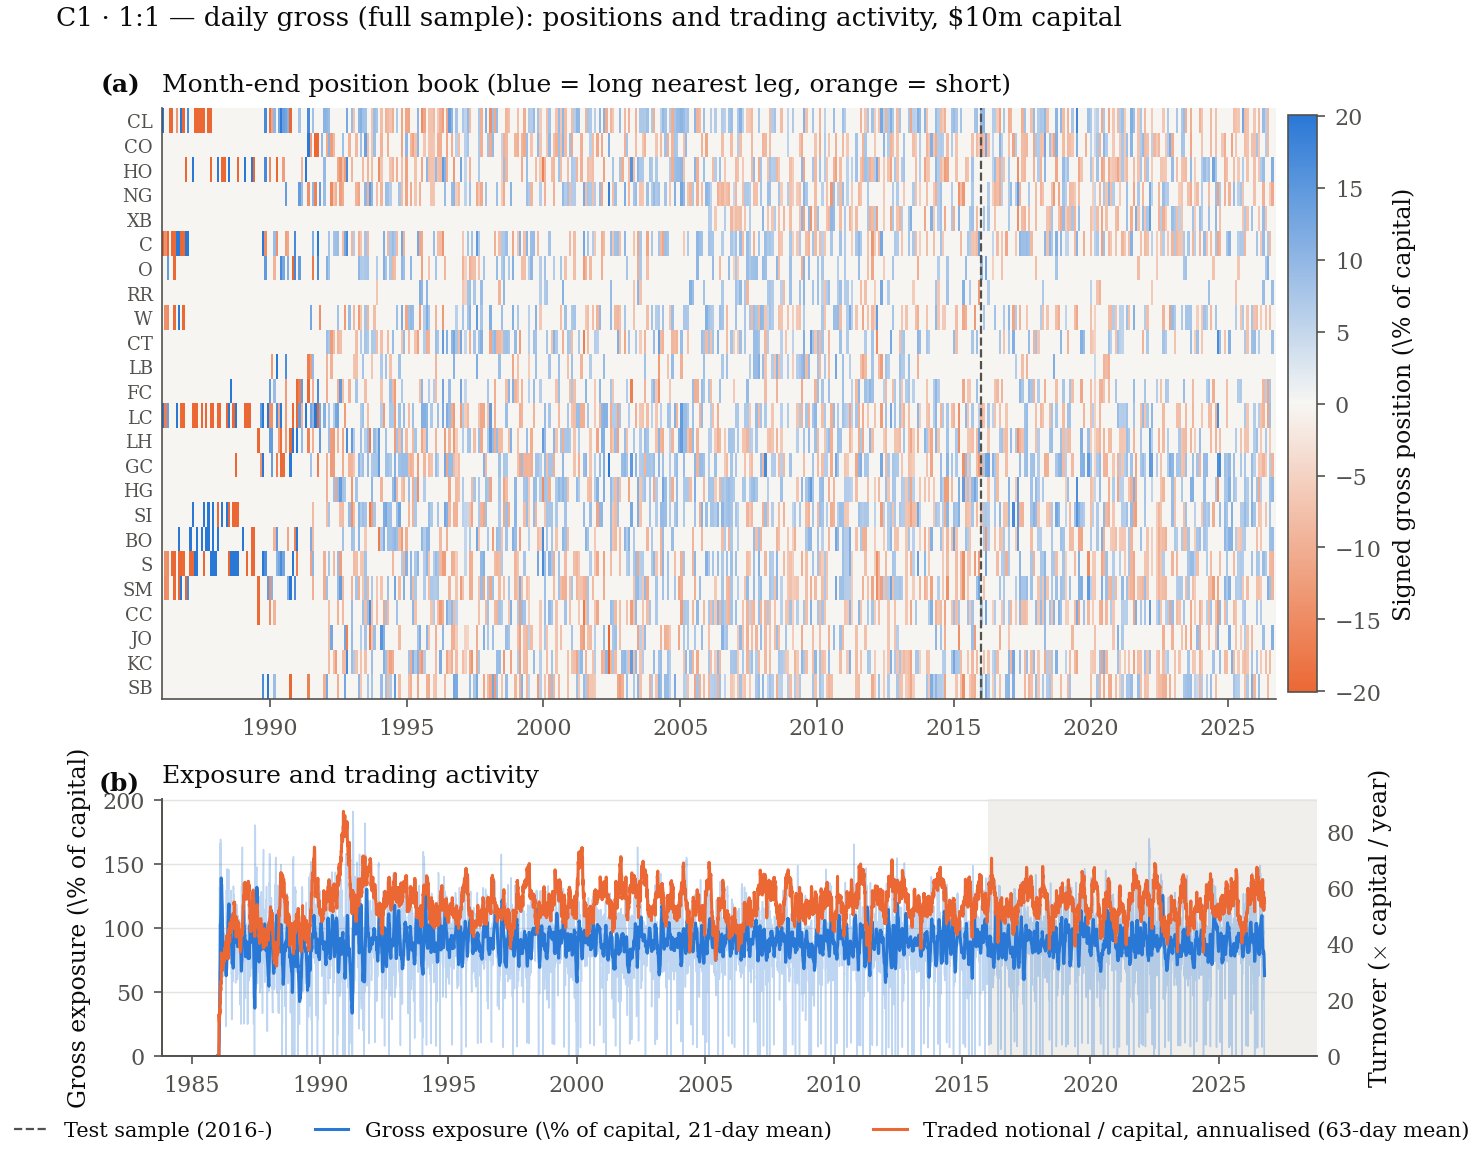

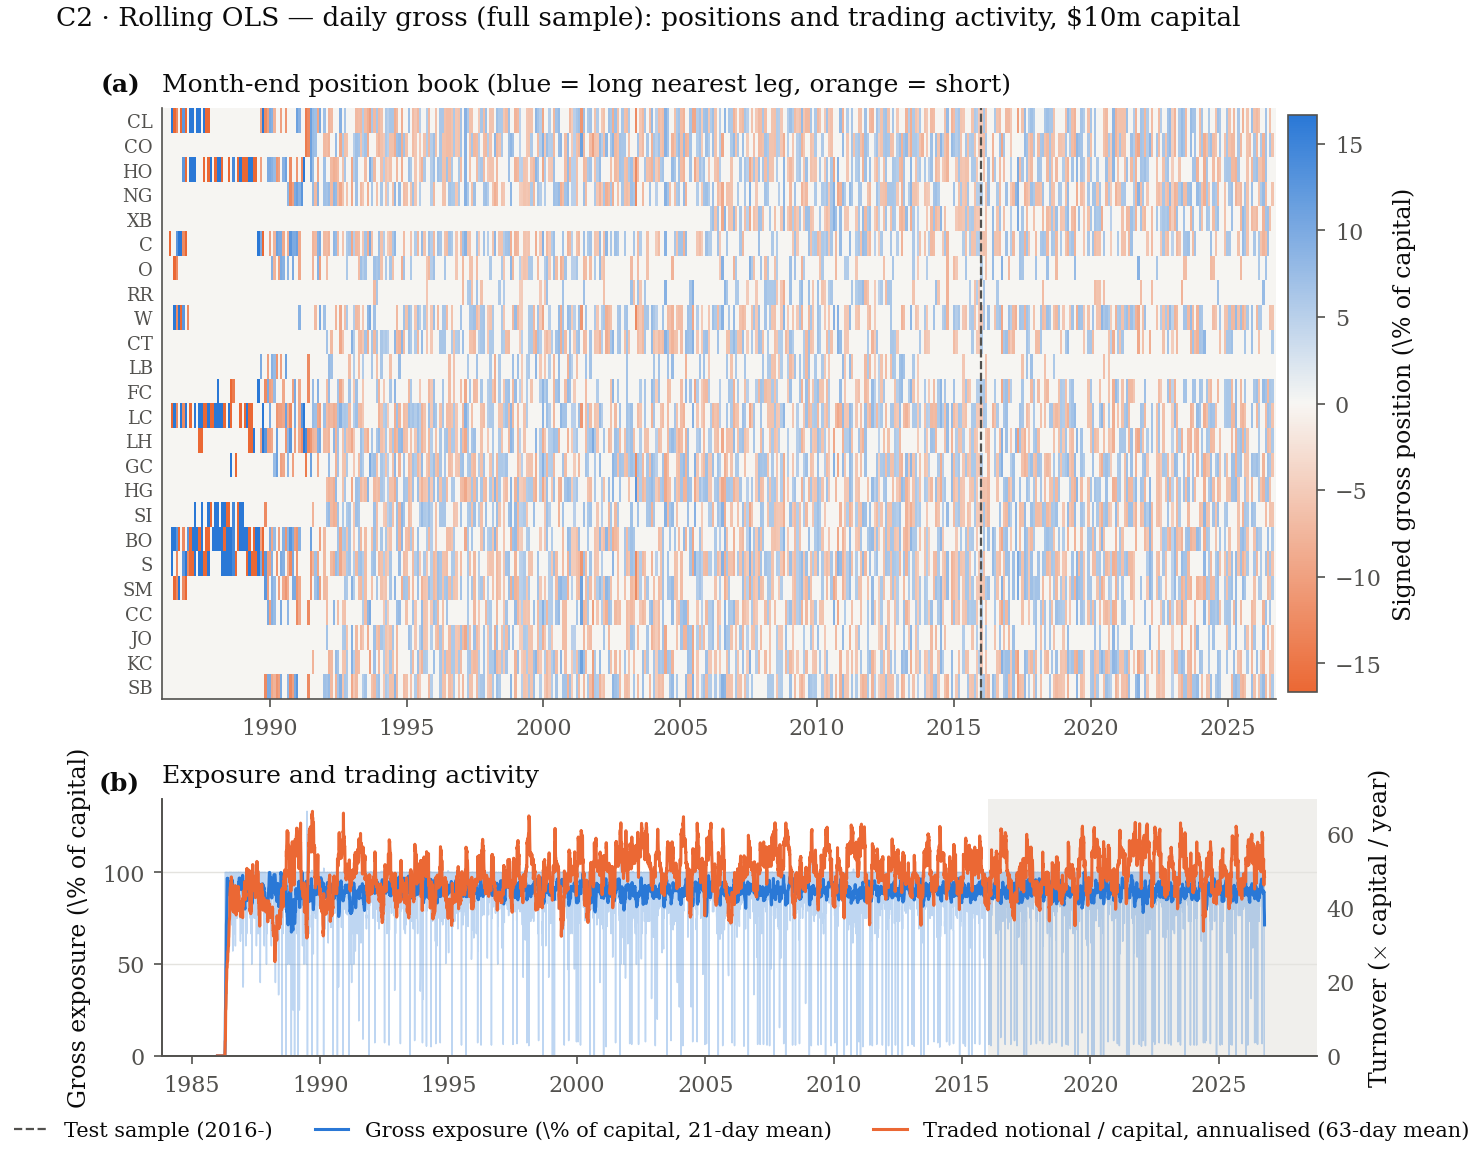

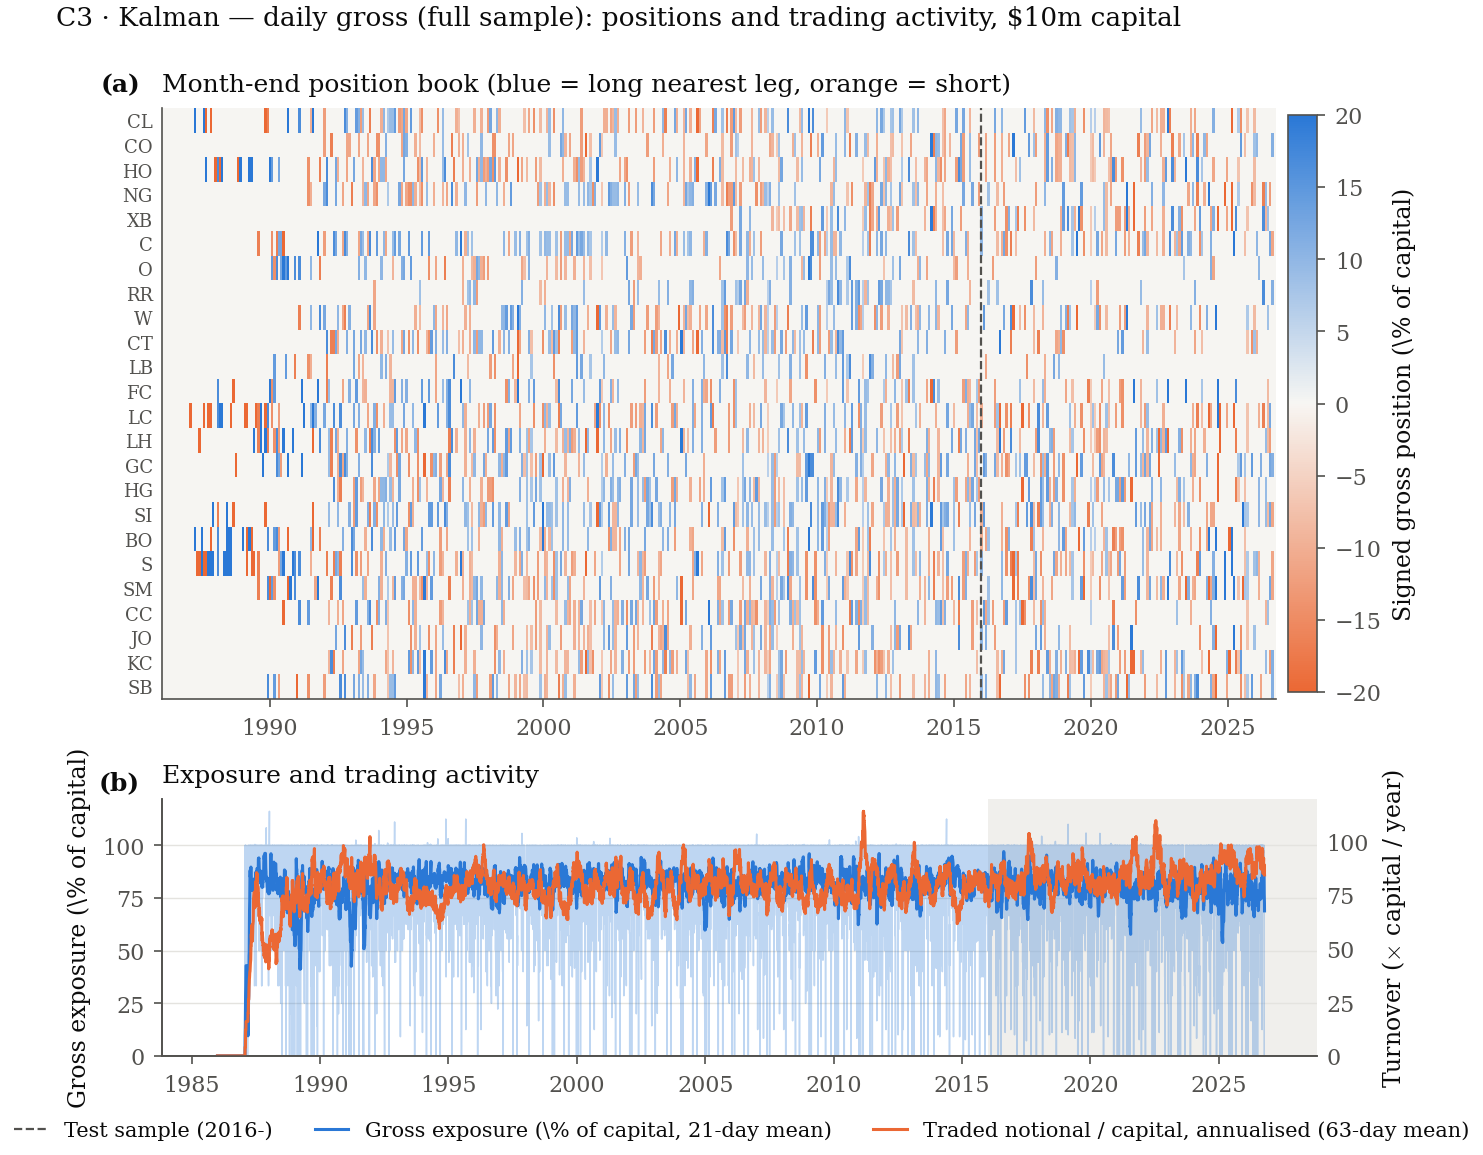

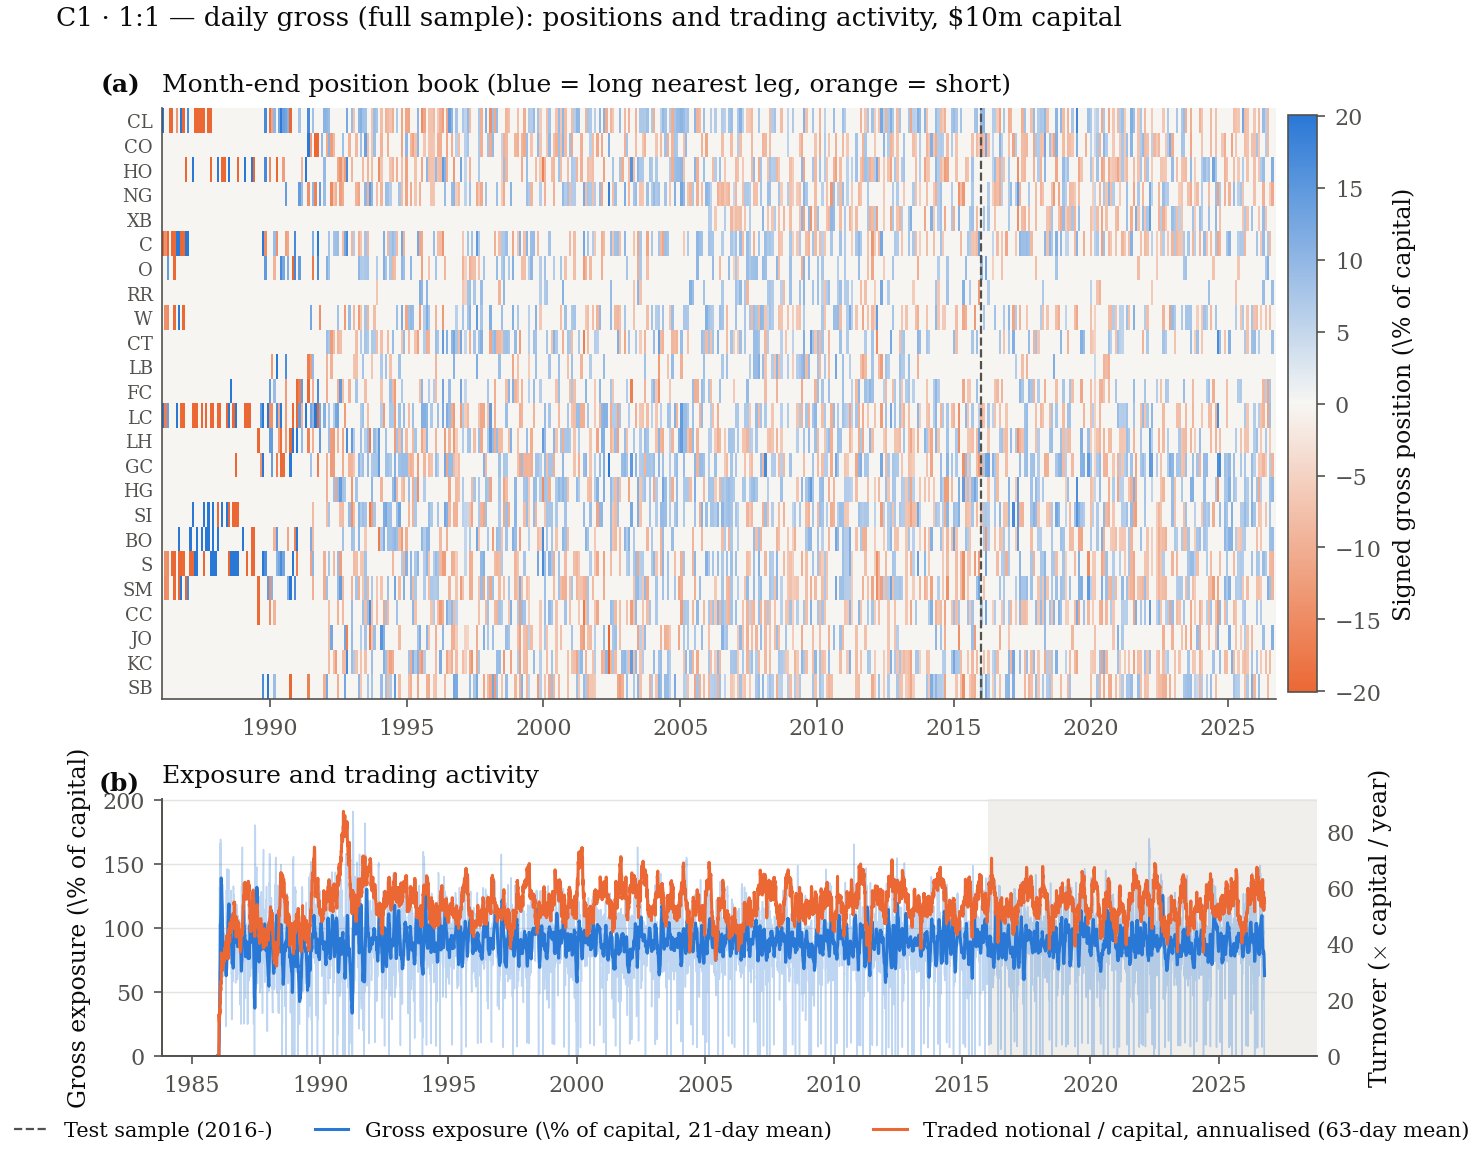

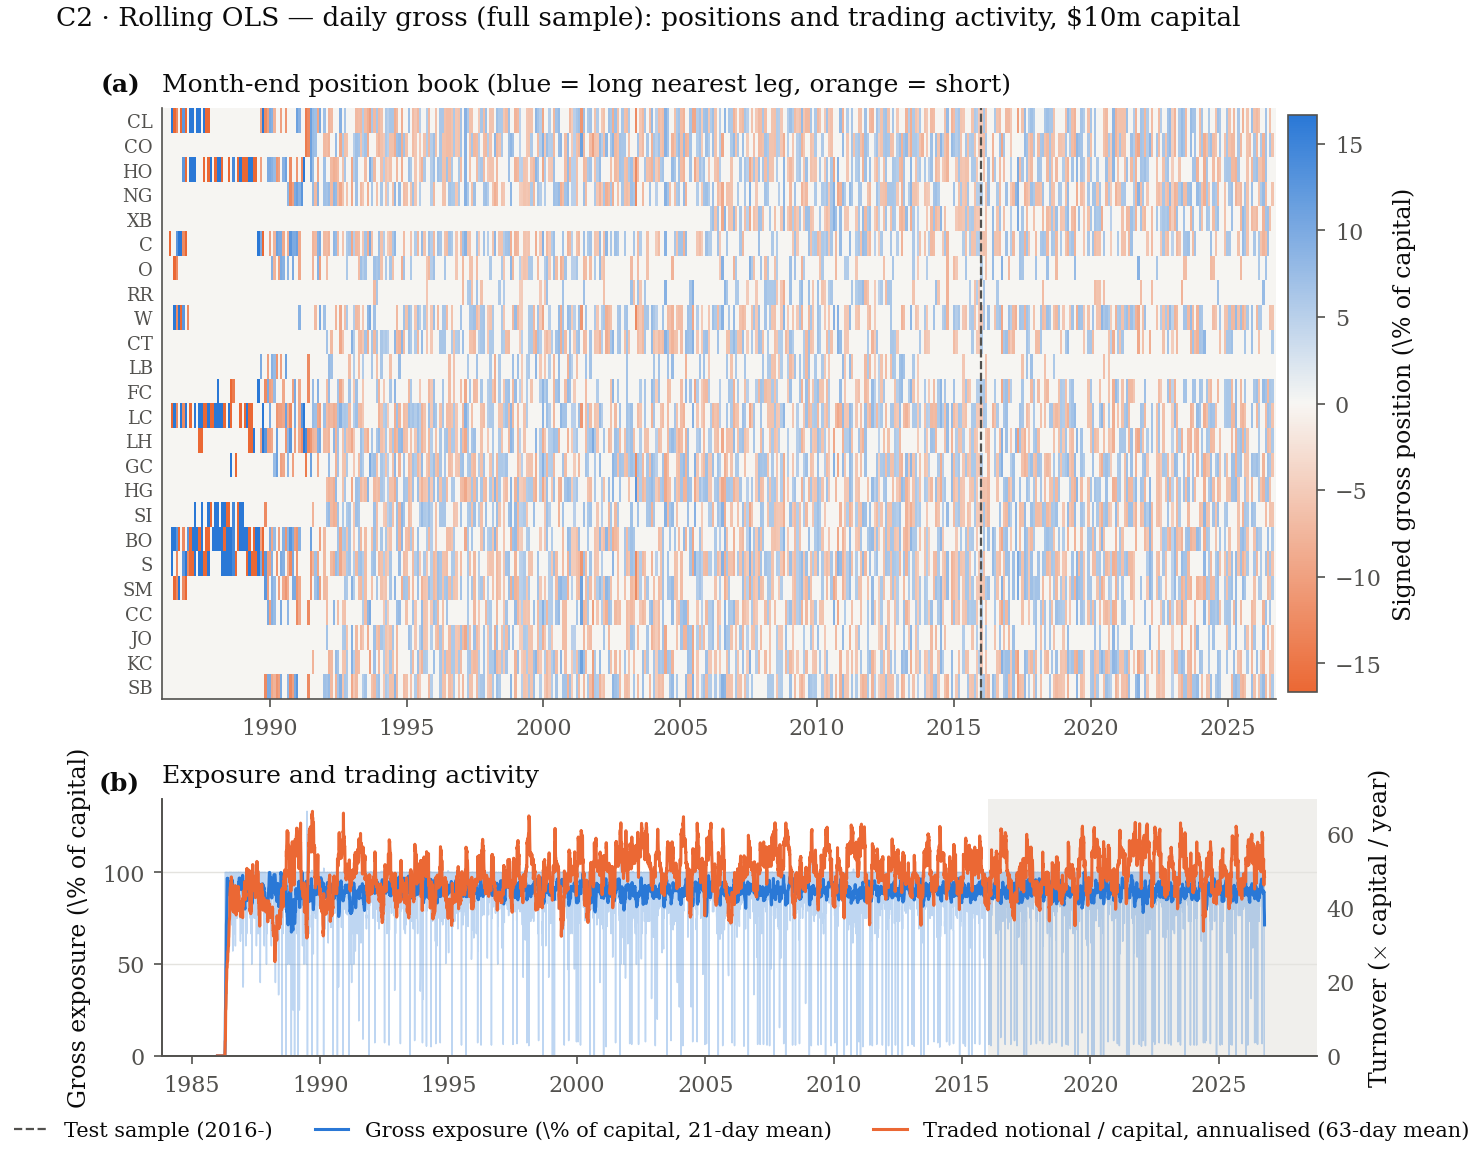

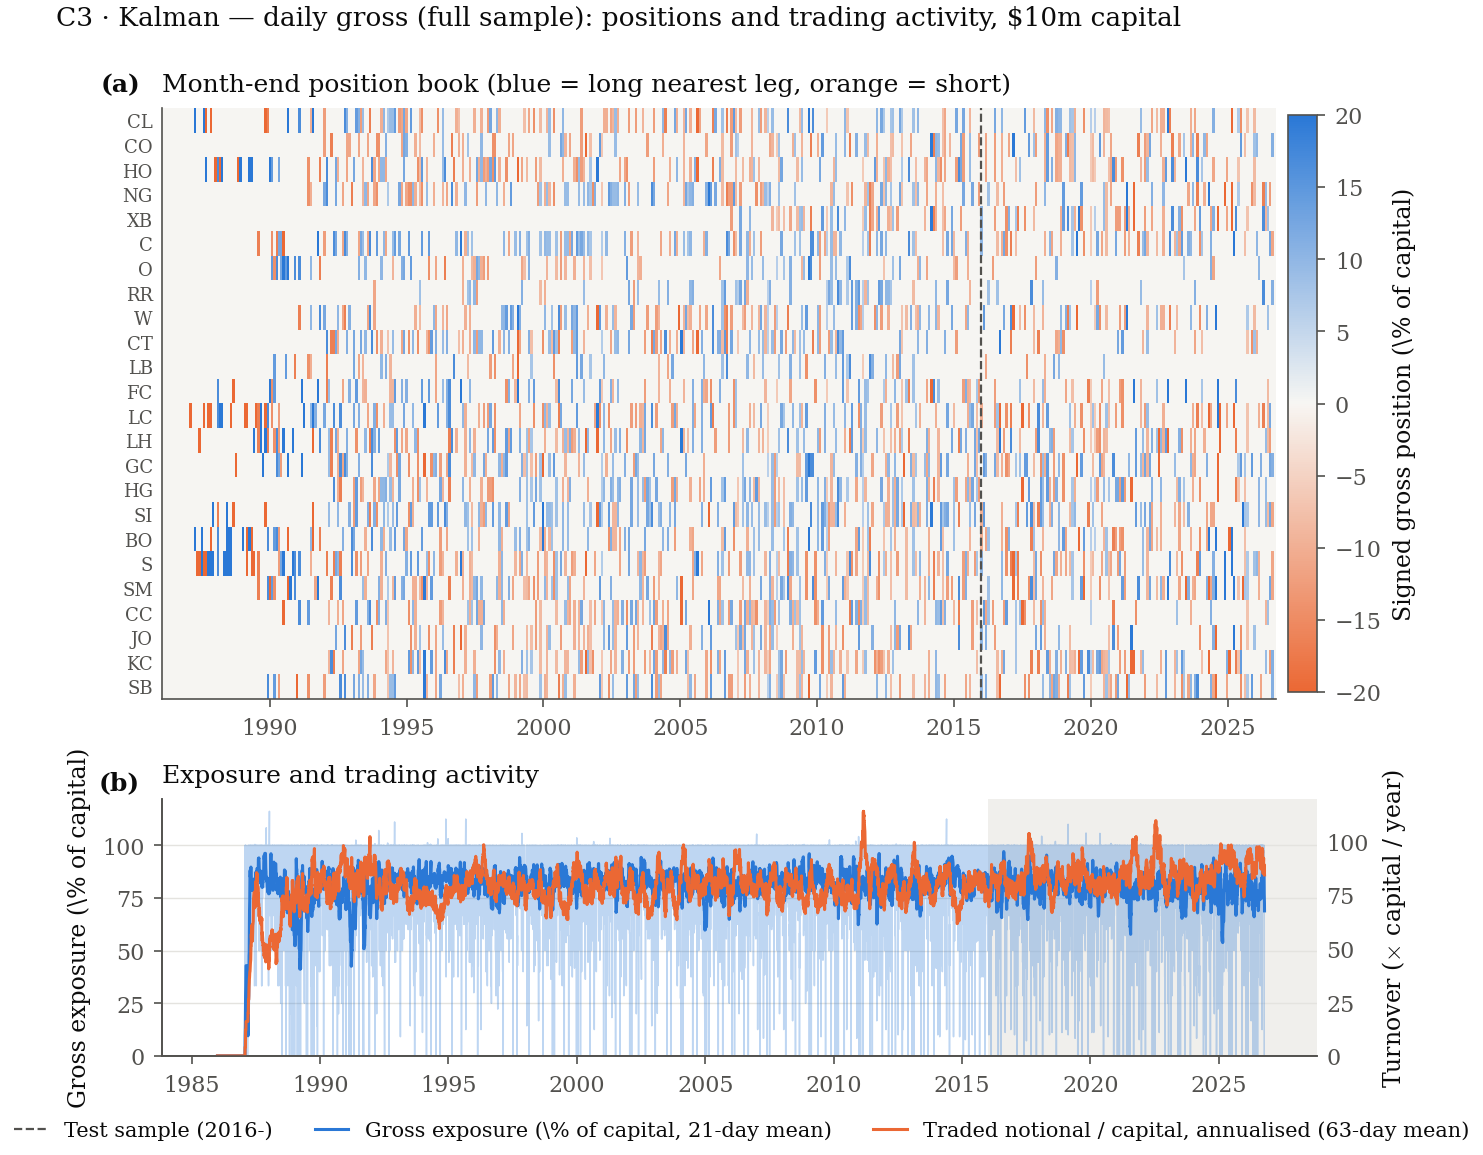

In [18]:
if full_loaded:
    for name, label in FULL_NAMES.items():
        fig = F.positions(
            full_loaded[name]["result"],
            f"{label} — daily gross (full sample)",
            root_order=ROOT_ORDER,
        )
        ps.save(fig, f"idea_c_daily_full_positions_{name}")
        display(fig)


### 12.3 Summary：gross SR、turnover、active roots

下表按 full / train / validation / test 四个 period 汇总 gross 结果。
`active_roots` 是该 period 内至少有一天 gross notional > 0 的 root 数。

**Test 2016–2026 行是 descriptive only。** 它不参与 D-027 的 selection/gate，
也不能用来调参；official weekly 结果仍以 D-019 的 v2 表为准。


In [19]:
if full_loaded:
    period_labels = [
        "full",
        "train 1986-2005",
        "validation 2006-2015",
        "test 2016-2026",
    ]
    rows = []
    for name, label in FULL_NAMES.items():
        performance = full_loaded[name]["performance"]
        positions = full_loaded[name]["positions"]
        for period in period_labels:
            start, end = c_daily.PERIODS[period]
            gross = performance.loc[
                performance["period"].eq(period)
                & performance["layer"].eq("gross")
            ].iloc[0]
            active = positions
            if start is not None:
                active = active.loc[active["date"] >= pd.Timestamp(start)]
            if end is not None:
                active = active.loc[active["date"] <= pd.Timestamp(end)]
            active_roots = int(
                active.groupby("root")["gross_notional"]
                .apply(lambda x: (x > 0).any())
                .sum()
            )
            rows.append(
                {
                    "variant": label,
                    "period": period,
                    "gross_ann_pct": gross["ann_ret_pct"],
                    "gross_sr": gross["sharpe"],
                    "turnover_x": gross["turnover_x"],
                    "active_roots": active_roots,
                }
            )
    display(pd.DataFrame(rows).round(3))


,variant,period,gross_ann_pct,gross_sr,turnover_x,active_roots
0,C1 · 1:1,full,0.251,0.193,54.254,24
1,C1 · 1:1,train 1986-2005,0.525,0.349,54.036,23
2,C1 · 1:1,validation 2006-2015,0.229,0.240,54.697,24
3,C1 · 1:1,test 2016-2026,-0.232,-0.196,54.247,24
4,C2 · Rolling OLS,full,-0.026,-0.024,49.172,24
5,C2 · Rolling OLS,train 1986-2005,-0.195,-0.159,47.656,23
6,C2 · Rolling OLS,validation 2006-2015,0.219,0.265,50.732,24
7,C2 · Rolling OLS,test 2016-2026,0.058,0.060,50.523,24
8,C3 · Kalman,full,0.218,0.125,77.812,24
9,C3 · Kalman,train 1986-2005,0.271,0.175,73.219,23


**Reading.** Full-sample daily gross NAV、positions 和 summary 现在都已持久化并可见；
D-027 的结论不变：C1 被顺序选择保留，但 validation gross SR 0.240 没过 0.4 gate；
descriptive test read 不会重新打开 C。
